# %% [markdown]
# IDMOD Microsimulation – GPU-Optimized Version with Full Vectorization
# --------------------------------------------------------------
# All operations on GPU with cuDF/CuPy. No CPU-GPU transfers inside loops.
# Copy into your Jupyter notebook.


# %% [markdown]
## 1. Imports & Setup

# %%
import cupy as cp
import cudf
import matplotlib.pyplot as plt
from scipy.stats import beta
import warnings

warnings.filterwarnings('ignore')
cp.random.seed(42)

# %% [markdown]
## 2. Global Settings & Precomputed GPU Arrays

# %%
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035
POP_SIZE = 62000

# Severity distribution
SEVERITY_DIST = cp.array([0.70, 0.30])

# Age distribution (0–4,...,90–94)
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST   = cp.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality
ABS_MORT = cp.array([
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
    0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
    0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])
MORT_HR = cp.array([2.0, 4.0])

# Fertility lookup table
FERT_AGE_SPEC = {
    (0,(15,19)):0.003,(0,(20,24)):0.008,(0,(25,29)):0.010,
    (0,(30,34)):0.007,(0,(35,45)):0.002,
    (1,(15,19)):0.001,(1,(20,24)):0.003,(1,(25,29)):0.004,
    (1,(30,34)):0.003,(1,(35,45)):0.001,
}
fert_data = []
for (s,(lo,hi)), rate in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity': s, 'age': age, 'rate': rate})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Diagnostics & utilities
YIELD_WGS = 0.45
U_BASE    = {0: 0.78, 1: 0.65}
U_BASE_CP = cp.array([U_BASE[i] for i in sorted(U_BASE)])
U_DIAG    = 0.02
U_CARER   = 0.05

# Costs & lookups
COST_LIVING = {0:16973, 1:(4452+59375)/2, 2:1727*52, 3:0}
lv_arr_gpu  = cp.array([COST_LIVING[i] for i in sorted(COST_LIVING)])
RESPITE_COST = 13024

# Education costs by (severity, support)
ed0 = cp.array([16107, 27903, 46733])  # severity 0, support 0-2
ed1 = cp.array([18958, 30789, 49604])  # severity 1

EI_HRS        = 185*5*52
MOBILITY_ALLW = 2493
EMP_LOSS      = {0:0,1:10000,2:0}
EMP_ARR_GPU   = cp.array([EMP_LOSS[i] for i in sorted(EMP_LOSS)])

NDIS_COST = 45000

# Morbidity & carer lookups
MORB_PROB  = {'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_KEYS  = list(MORB_PROB.keys())
MORB_COST  = {k: v for k, v in zip(MORB_KEYS, [2000,1500,1000])}
MORB_QALY  = {k: v for k, v in zip(MORB_KEYS, [0.04,0.03,0.05])}
MORB_COST_CP = cp.array([MORB_COST[k] for k in MORB_KEYS])
MORB_QALY_CP = cp.array([MORB_QALY[k] for k in MORB_KEYS])

CARER_HOURS = {0:5,1:15}
CARER_ARR_GPU = cp.array([CARER_HOURS[i] for i in sorted(CARER_HOURS)])
WAGE_HR       = 38


# %% [markdown]
## 3. Cohort Generator (GPU)

# %%
def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0,5,n)).astype(int)

def gen_population_gpu(n, familial_prop):
    ages       = sample_ages_gpu(n)
    sex        = cp.random.choice(2, n)
    sev        = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial   = cp.random.random(n) < familial_prop
    diagnosed  = cp.zeros(n, dtype=bool)
    living     = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    resp       = cp.random.random(n) < 0.3
    mobility   = cp.random.random(n) < 0.2
    school     = cp.where(ages<5, -1, cp.where(ages<12, 0, 1))
    support    = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses        = cp.random.choice(5, n)
    df = cudf.DataFrame({
        'age': ages, 'sex': sex, 'severity': sev, 'familial': familial,
        'diagnosed': diagnosed, 'living': living, 'employment': employment,
        'uses_respite': resp, 'needs_mobility': mobility, 'school': school,
        'support': support, 'ses': ses
    })
    df['annual_cost'] = 0.0
    df['annual_qaly'] = 0.0
    return df

# %% [markdown]
## 4. Simulation System

# %%
class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop):
        self.pop = gen_population_gpu(pop_size, familial_prop)

    def _mortality(self):
        ages = self.pop['age'].to_cupy()
        # vectorized mortality mask
        mask = cp.random.random(len(ages)) > (ABS_MORT[(ages//5).astype(int)] * MORT_HR[self.pop['severity'].to_cupy()])
        self.pop = self.pop.iloc[mask].reset_index(drop=True)

    def _fertility(self, familial_prop):
        moms = self.pop[(self.pop['sex']==0) & self.pop['age'].between(15,45)]
        if moms.empty:
            return
        mr = moms.merge(FERT_RATES_GPU, on=['severity','age'], how='left').fillna({'rate':0})
        # use .values to get cupy view
        rates = mr['rate'].values
        births = cp.random.random(len(rates)) < rates
        n = int(births.sum())
        if n > 0:
            babies = gen_population_gpu(n, familial_prop)
            babies['age'] = 0
            # direct GPU selection of familial flags
            fam_flags = mr['familial'].iloc[cp.nonzero(births)[0]].reset_index(drop=True)
            babies['familial'] = fam_flags
            self.pop = cudf.concat([self.pop, babies], ignore_index=True)

    def _diagnosis(self):
        mask = (self.pop['familial']) & (~self.pop['diagnosed'])
        self.pop.loc[mask, 'diagnosed'] = cp.random.random(mask.sum()) < YIELD_WGS

    def _cost_qaly(self):
        df = self.pop
        df['annual_cost'] = 0.0
        df['annual_qaly'] = 0.0
        # living
        df['annual_cost'] += lv_arr_gpu[df['living'].to_cupy()]
        # respite
        df.loc[df['uses_respite'], 'annual_cost'] += RESPITE_COST
        # education by severity & support
        mask0 = df['school']==0
        mask1 = df['school']==1
        df.loc[mask0, 'annual_cost'] += ed0[df.loc[mask0, 'support'].to_cupy()]
        df.loc[mask1, 'annual_cost'] += ed1[df.loc[mask1, 'support'].to_cupy()]
        # early intervention
        df.loc[df['school']<0, 'annual_cost'] += EI_HRS
        # mobility subsidy
        df.loc[df['needs_mobility'], 'annual_cost'] -= MOBILITY_ALLW
        # employment loss
        df['annual_cost'] += EMP_ARR_GPU[df['employment'].to_cupy()]
        # NDIS
        df.loc[(df['diagnosed']) & (df['severity']==1), 'annual_cost'] += NDIS_COST
                        # morbidity & QALY
        base_flags = cp.random.random(len(df))  # shared RNG call
        for i, m in enumerate(MORB_KEYS):
            flag = f'has_{m}'
            df[flag] = base_flags < MORB_PROB[m]
            # convert cupy scalar to Python float for cudf compatibility
            cost_val = float(MORB_COST_CP[i].item())
            qaly_val = float(MORB_QALY_CP[i].item())
            df['annual_cost'] += df[flag] * cost_val
            df['annual_qaly']  -= df[flag] * qaly_val
        # carer productivity
        df['annual_cost'] += CARER_ARR_GPU[df['severity'].to_cupy()] * 52 * WAGE_HR
        # utilities
        df['annual_qaly'] += U_BASE_CP[df['severity'].to_cupy()] + df['diagnosed']*U_DIAG + U_CARER
        self.pop = df

    def step(self, params):
        self._mortality()
        self._fertility(params['familial_prop'])
        self._diagnosis()
        self._cost_qaly()

# %% [markdown]
## 5. run_sim_gpu Helper

# %%
def run_sim_gpu(params, pop_size=POP_SIZE, years=range(START_YEAR, END_YEAR+1)):
    gpu_c = cp.array(0.0)
    gpu_q = cp.array(0.0)
    sim   = PopulationSystemGPU(pop_size, params['familial_prop'])
    for t in range(len(years)):
        sim.step(params)
        disc = 1/((1+DISCOUNT)**t)
        gpu_c += sim.pop['annual_cost'].sum() * disc
        gpu_q += sim.pop['annual_qaly'].sum() * disc
    return float(gpu_c.get()), float(gpu_q.get())

# %% [markdown]
## 6. Deterministic Scenarios

# %%
scenarios = {'low':0.10,'base':0.165,'high':0.23}
res       = []
for name,val in scenarios.items():
    c,q = run_sim_gpu({'familial_prop':val}, pop_size=20000)
    res.append({'scenario':name,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
det_df = cudf.DataFrame(res)
det_df.to_csv('deterministic_summary.csv', index=False)
print(det_df)
plt.bar(det_df['scenario'].values_host, det_df['ICER'].values_host/1000)
plt.title('Deterministic ICERs ($k/QALY)')
plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

# %%
psa=[]
for _ in range(300):
    samp={'familial_prop':beta.rvs(17,83),'yield_wgs':beta.rvs(45,55)}
    c,q=run_sim_gpu(samp,pop_size=8000)
    psa.append({'cost':c,'qaly':q})
psa_df=cudf.DataFrame(psa)
psa_df.to_csv('psa_samples.csv', index=False)


# %% [markdown]
## 8. CEAC & EVPI

# %%
# WTP values on GPU, then bring to host for CEAC/EVPI
wtp_gpu = cp.linspace(0,150000,40)
wtp = wtp_gpu.get()  # numpy array of floats
costs = psa_df['cost'].to_pandas()
qalys = psa_df['qaly'].to_pandas()
prob  = []
evpi  = []
for w in wtp:
    # ensure w is Python float
    w_f = float(w)
    nmb = qalys * w_f - costs
    prob.append((nmb > 0).mean())
    evpi.append(nmb.max() - max(nmb.mean(), 0))
# Plot CEAC and EVPI
plt.figure(); plt.plot(wtp, prob); plt.title('CEAC'); plt.xlabel('WTP'); plt.ylabel('P(CE)'); plt.show()
plt.figure(); plt.plot(wtp, evpi); plt.title('EVPI'); plt.xlabel('WTP'); plt.ylabel('EVPI ($)'); plt.show()

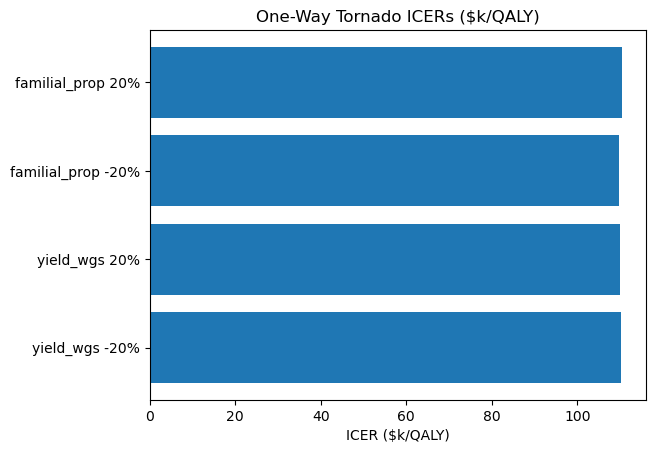

In [19]:
import json

import cudf
import cupy as cp
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import beta


def run_archived_fragment_10(*, run_sim_gpu):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """

    import cudf
    import matplotlib.pyplot as plt

    ## 9. One-Way Tornado

    # %%
    torr = []
    for param in ["yield_wgs", "familial_prop"]:
        base = 0.45 if param == "yield_wgs" else 0.165
        for pct in [-0.2, 0.2]:
            p = {"familial_prop": 0.165, "yield_wgs": 0.45}
            p[param] = base * (1 + pct)
            c, q = run_sim_gpu(p, pop_size=10000)
            torr.append({"param": param, "change": f"{int(pct * 100)}%", "ICER": c / q})
    # Build DataFrame
    tor_df = cudf.DataFrame(torr)
    # Convert to host for plotting
    labels = tor_df["param"].to_pandas() + " " + tor_df["change"].to_pandas()
    values = tor_df["ICER"].to_pandas() / 1000
    plt.figure()
    plt.barh(labels, values)
    plt.title("One-Way Tornado ICERs ($k/QALY)")
    plt.xlabel("ICER ($k/QALY)")
    plt.show()
    return locals()

# %% [markdown]
## 10. PSA Histograms & CEAF

# %%
costs = psa_df['cost'].to_pandas()
qalys = psa_df['qaly'].to_pandas()
plt.hist(costs, bins=30); plt.title('PSA ΔCost'); plt.show()
plt.hist(qalys, bins=30); plt.title('PSA ΔQALY'); plt.show()
evf=[]
for w in wtp:
    nmb = qalys*w - costs
    best = nmb.max()
    evf.append((nmb==best).mean())
plt.plot(wtp, evf); plt.title('CEAF'); plt.show()

# %% [markdown]
## 11. Subgroup Analyses

# %%
sg=[]
for code,label in [(0,'Mild'),(1,'Moderate')]:
    orig=SEVERITY_DIST.copy()
    SEVERITY_DIST[:] = cp.array([1.0,0.0]) if code==0 else cp.array([0.0,1.0])
    c,q = run_sim_gpu({'familial_prop':0.165},pop_size=20000)
    sg.append({'subgroup':label,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
    SEVERITY_DIST[:] = orig
sg_df=cudf.DataFrame(sg)
plt.errorbar(sg_df['subgroup'].to_pandas(), sg_df['ICER'].to_pandas()/1000, yerr=0, fmt='o')
plt.title('Subgroup ICERs'); plt.show()


# %% [markdown]
# IDMOD Microsimulation – Enhanced GPU Version (No Microdata)
# -------------------------------------------------------------
# Extends core engine with policy scenarios, QoL trajectories,
# cost modules, welfare payments, lifespan truncation,
# retrospective vs prospective arms, and intermediate outputs.
# Requires: cudf, cupy, scipy, matplotlib

# %% [markdown]
## 1. Imports & Setup

# %%
import cupy as cp
import cudf
import matplotlib.pyplot as plt
from scipy.stats import beta
import warnings
warnings.filterwarnings('ignore')
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & Precomputed GPU Arrays

# %%
# Time horizon
START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR+1))
DISCOUNT = 0.035

# Demography
POP_SIZE = 62000
SEVERITY_DIST = cp.array([0.70, 0.30])  # mild, moderate
AGE_BREAKS = cp.arange(0,95,5)
AGE_DIST   = cp.array([0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
                       0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012])
AGE_DIST /= AGE_DIST.sum()

# Life expectancy by severity
LIFE_EXP = {0:74, 1:54}

# Mortality
ABS_MORT = cp.array([0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,0.0011,0.0019,
                     0.0035,0.0055,0.0085,0.0130,0.0200,0.0350,0.0600,0.0950,0.1500,0.2500])
MORT_HR  = cp.array([2.0, 4.0])

# Fertility lookup
FERT_AGE_SPEC = {(0,(15,19)):0.003,(0,(20,24)):0.008,(0,(25,29)):0.010,(0,(30,34)):0.007,(0,(35,45)):0.002,
                 (1,(15,19)):0.001,(1,(20,24)):0.003,(1,(25,29)):0.004,(1,(30,34)):0.003,(1,(35,45)):0.001}
fert_data=[]
for (s,(lo,hi)),r in FERT_AGE_SPEC.items():
    for age in range(lo,hi+1): fert_data.append({'severity':s,'age':age,'rate':r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Diagnostic yields
DEFAULT_YIELD = 0.45

# QoL parameters
U_BASE = {0:0.78,1:0.65}            # base utility by severity
U_DECAY_RATE = 0.0005               # annual decline factor
U_DIAG = 0.02                       # gain from diagnosis
U_CARER = 0.05                      # carer utility impact

# Precompute GPU arrays
U_BASE_CP     = cp.array([U_BASE[i] for i in sorted(U_BASE)])

# Costs
COST_INPATIENT  = {0:5000, 1:15000}
COST_OUTPATIENT = {0:1000, 1:3000}
COST_PHARMACY   = {0:200,  1:500}
COST_INP_CP     = cp.array([COST_INPATIENT[i] for i in sorted(COST_INPATIENT)])
COST_OUTP_CP    = cp.array([COST_OUTPATIENT[i] for i in sorted(COST_OUTPATIENT)])
COST_PHARM_CP   = cp.array([COST_PHARMACY[i] for i in sorted(COST_PHARMACY)])

# Education & welfare
EDU_COST0 = cp.array([16107,27903,46733])
EDU_COST1 = cp.array([18958,30789,49604])
EI_HRS    = 185*5*52
RESPITE   = 13024
MOBILITY  = 2493
WELFARE   = {0:3000,1:8000}
WELFARE_CP= cp.array([WELFARE[i] for i in sorted(WELFARE)])

# Employment loss
EMP_LOSS  = {0:0,1:10000,2:0}
EMP_CP    = cp.array([EMP_LOSS[i] for i in sorted(EMP_LOSS)])

# Morbidity
MORB_PROB   = {'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_KEYS   = list(MORB_PROB.keys())
MORB_COST   = {'epilepsy':2000,'asd':1500,'mental':1000}
MORB_QALY   = {'epilepsy':0.04,'asd':0.03,'mental':0.05}
MORB_COST_CP= cp.array([MORB_COST[k] for k in MORB_KEYS])
MORB_QALY_CP= cp.array([MORB_QALY[k] for k in MORB_KEYS])

# %% [markdown]
## 3. Cohort Generator (GPU)

# %%
def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0,5,n)).astype(int)

def gen_population_gpu(n, familial_prop, arm='prospective'):
    ages       = sample_ages_gpu(n)
    sex        = cp.random.choice(2,n)
    sev        = cp.random.choice(2,n,p=SEVERITY_DIST)
    familial   = cp.random.random(n)<familial_prop
    diagnosed  = cp.zeros(n,dtype=bool) if arm=='prospective' else cp.random.random(n)<DEFAULT_YIELD if arm=='retrospective' else cp.zeros(n,dtype=bool)
    living     = cp.random.choice(4,n,p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3,n,p=cp.array([0.7,0.2,0.1]))
    resp       = cp.random.random(n)<0.3
    mobility   = cp.random.random(n)<0.2
    school     = cp.where(ages<5,-1,cp.where(ages<12,0,1))
    support    = cp.random.choice(3,n,p=cp.array([0.5,0.3,0.2]))
    ses        = cp.random.choice(5,n)
    df         = cudf.DataFrame({
        'age':ages,'sex':sex,'severity':sev,'familial':familial,
        'diagnosed':diagnosed,'living':living,'employment':employment,
        'uses_respite':resp,'needs_mobility':mobility,'school':school,
        'support':support,'ses':ses
    })
    df['annual_cost']=0.0; df['annual_qaly']=0.0
    return df

# %% [markdown]
## 4. Simulation System with Enhancements

# %%
class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm='prospective'):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df['age'].to_cupy()
        # apply base mortality + excess
        mask = cp.random.random(len(ages)) > ABS_MORT[(ages//5).astype(int)]*MORT_HR[df['severity'].to_cupy()]
        # lifespan truncation
        mask &= ages < cp.array([LIFE_EXP[s] for s in df['severity'].to_pandas()])
        self.pop = df.iloc[mask].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df['sex']==0)&df['age'].between(15,45)]
        if moms.empty: return
        mr    = moms.merge(FERT_RATES_GPU,on=['severity','age'],how='left').fillna({'rate':0})
        rates = mr['rate'].values  # cupy view
        births= cp.random.random(len(rates))<rates
        n     = int(births.sum())
        if n>0:
            babies=gen_population_gpu(n,familial_prop,self.arm)
            babies['age']=0
            fam_flags=mr['familial'].iloc[cp.nonzero(births)[0]].reset_index(drop=True)
            babies['familial']=fam_flags
            self.pop=cudf.concat([df,babies],ignore_index=True)

    def _diagnosis(self, params):
        """
        Diagnosis step: prospective arm uses genomic testing after min_test_age;
        retrospective arm seeded at initialization.
        """
        if self.arm == 'prospective':
            min_age = params.get('min_test_age', 0)
            mask = (~self.pop['diagnosed']) & self.pop['familial'] & (self.pop['age'] >= min_age)
            self.pop.loc[mask, 'diagnosed'] = cp.random.random(mask.sum()) < params['yield_wgs']
        # retrospective arm remains as initialized
    def _cost_qaly(self, year, params):
        df = self.pop
        # Base utility with age decay
        base_u = U_BASE_CP[df['severity'].to_cupy()] * cp.exp(-U_DECAY_RATE * (df['age'].to_cupy() - 20).clip(0))
        df['annual_qaly'] = base_u + df['diagnosed']*U_DIAG + U_CARER
        # Costs: inpatient, outpatient, pharmacy
        df['annual_cost'] = COST_INP_CP[df['severity'].to_cupy()] + COST_OUTP_CP[df['severity'].to_cupy()] + COST_PHARM_CP[df['severity'].to_cupy()]
        # Education
        m0 = df['school']==0; m1=df['school']==1
        df.loc[m0,'annual_cost'] += EDU_COST0[df.loc[m0,'support'].to_cupy()]
        df.loc[m1,'annual_cost'] += EDU_COST1[df.loc[m1,'support'].to_cupy()]
        # EI, respite, mobility
        df.loc[df['school']<0,'annual_cost'] += EI_HRS
        df.loc[df['uses_respite'],'annual_cost'] += RESPITE
        df.loc[df['needs_mobility'],'annual_cost'] -= MOBILITY
        # Welfare
        df['annual_cost'] += WELFARE_CP[df['severity'].to_cupy()]
        # Employment loss
        df['annual_cost'] += EMP_CP[df['employment'].to_cupy()]
        # Morbidity
        flags = cp.random.random(len(df))
        for i,k in enumerate(MORB_KEYS):
            mask = flags < MORB_PROB[k]
            df['annual_cost'] += mask.astype(int)*MORB_COST_CP[i]
            df['annual_qaly']  -= mask.astype(int)*MORB_QALY_CP[i]
        # Discount
        disc = 1/((1+DISCOUNT)**(year-START_YEAR))
        df['annual_cost'] *= disc
        df['annual_qaly'] *= disc
        self.pop = df

    def step(self, year, params):
        self._mortality()
        self._fertility(params['familial_prop'])
        self._diagnosis(params)
        self._cost_qaly(year, params)

# %% [markdown]
## 5. run_scenario Helper (Two Arms, Intermediate Outputs)

# %%
def run_scenario(params, pop_size=POP_SIZE):
    """
    Run both retrospective and prospective arms, capturing intermediate outputs.
    """
    outputs = {
        'arm': [], 'year': [], 'pop_size': [],
        'sev_mild': [], 'sev_mod': [],
        'diagnosed_pct': [], 'costs': [], 'qalys': [],
        'ses_q0_pct': [], 'ses_q1_pct': [], 'ses_q2_pct': [], 'ses_q3_pct': [], 'ses_q4_pct': []
    }
    results = {}
    for arm in ['retrospective', 'prospective']:
        sim = PopulationSystemGPU(pop_size, params['familial_prop'], arm)
        cum_c = 0.0; cum_q = 0.0
        for yr in YEARS:
            sim.step(yr, params)
            df = sim.pop
            # Severity counts
            sev0 = int((df['severity'] == 0).sum())
            sev1 = int((df['severity'] == 1).sum())
            # Diagnosis pct
            diag_pct = float(df['diagnosed'].mean()) * 100
            # SES distribution %
            ses_fracs = [(df['ses'] == i).mean() * 100 for i in range(5)]
            # Annual totals
            year_c = float(df['annual_cost'].sum())
            year_q = float(df['annual_qaly'].sum())
            # Append outputs
            outputs['arm'].append(arm)
            outputs['year'].append(yr)
            outputs['pop_size'].append(len(df))
            outputs['sev_mild'].append(sev0)
            outputs['sev_mod'].append(sev1)
            outputs['diagnosed_pct'].append(diag_pct)
            outputs['costs'].append(year_c)
            outputs['qalys'].append(year_q)
            for i, pct in enumerate(ses_fracs):
                outputs[f'ses_q{i}_pct'].append(pct)
            cum_c += year_c
            cum_q += year_q
        results[arm] = {'cost': cum_c, 'qaly': cum_q}
    # Build GPU DataFrame of intermediate outputs
    out_df = cudf.DataFrame(outputs)
    return results, out_df

# %% [markdown]
## 6. Policy Scenario Manager

# %%
policy_scenarios = {
    'Base': {'familial_prop':0.165, 'yield_wgs':0.45},
    'HighCoverage': {'familial_prop':0.165, 'yield_wgs':0.70},
    'TargetedAge': {'familial_prop':0.165, 'yield_wgs':0.45, 'min_test_age':25}
}
policy_results = {}
for name, ps in policy_scenarios.items():
    res, intermediate = run_scenario(ps, pop_size=20000)
    policy_results[name] = {'results':res, 'intermediate':intermediate}
    intermediate.to_csv(f'intermediate_{name}.csv', index=False)

# %% [markdown]
## 7. Summaries & Plots

# %%
# Compare retrospective vs prospective
for name, pr in policy_results.items():
    print(f"=== Scenario: {name} ===")
    print(pr['results'])
# Plot population over time for Base scenario
base_int = policy_results['Base']['intermediate'].to_pandas()
plt.plot(base_int['year'], base_int['pop_size']); plt.title('Population Over Time (Base)'); plt.show()


  scenario         dCost        dQALY          ICER
0      low -2.538294e+08 -4006.539320  63353.777058
1     base -2.615292e+07 -2013.002837  12991.994709
2     high  2.687448e+08  5785.150301  46454.246165


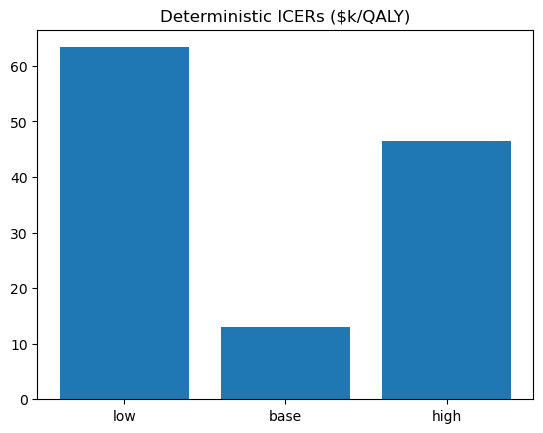

In [9]:
def run_archived_fragment_21(*, DEFAULT_YIELD, run_scenario):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 8. Deterministic Scenario Comparison

    # %%
    scenarios = {"low": 0.10, "base": 0.165, "high": 0.23}
    det = []
    for name, val in scenarios.items():
        res, _ = run_scenario(
            {"familial_prop": val, "yield_wgs": DEFAULT_YIELD}, pop_size=20000
        )
        dc = res["prospective"]["cost"] - res["retrospective"]["cost"]
        dq = res["prospective"]["qaly"] - res["retrospective"]["qaly"]
        det.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": dc / dq})
    det_df = cudf.DataFrame(det)
    det_df.to_csv("deterministic_summary.csv", index=False)
    print(det_df)
    plt.figure()
    plt.bar(det_df["scenario"].to_pandas(), det_df["ICER"].to_pandas() / 1000)
    plt.title("Deterministic ICERs ($k/QALY)")
    plt.show()
    return locals()

In [10]:
def run_archived_fragment_22(*, run_scenario):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 9. Probabilistic Sensitivity Analysis (PSA)

    # %%
    import pandas as pd

    psa = []
    for _ in range(200):
        samp = {"familial_prop": beta.rvs(17, 83), "yield_wgs": beta.rvs(45, 55)}
        res, _ = run_scenario(samp, pop_size=10000)
        dc = res["prospective"]["cost"] - res["retrospective"]["cost"]
        dq = res["prospective"]["qaly"] - res["retrospective"]["qaly"]
        psa.append({"dCost": dc, "dQALY": dq})
    psa_df = pd.DataFrame(psa)
    psa_df.to_csv("psa_samples.csv", index=False)
    return locals()

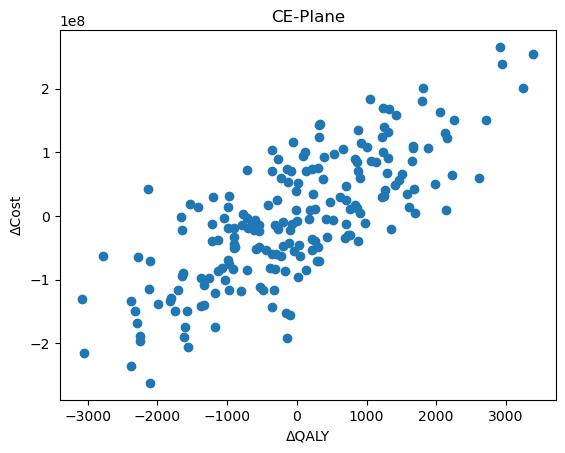

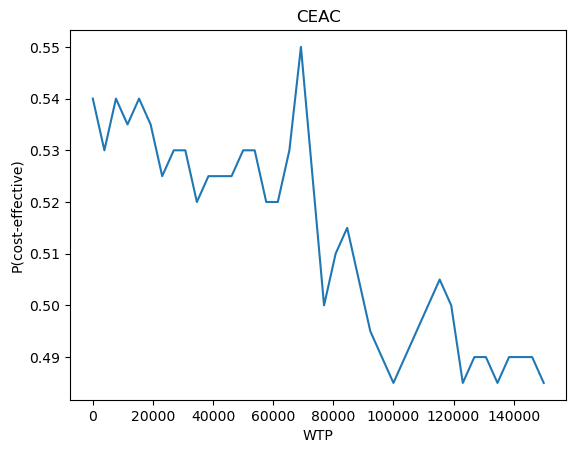

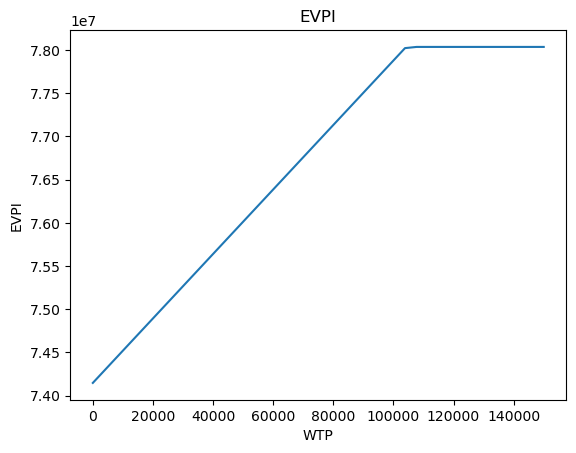

In [12]:
def run_archived_fragment_23(*, psa_df):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 10. CE-Plane, CEAC & EVPI

    import numpy as np

    # %%
    wtp = np.linspace(0, 150000, 40)
    nb = psa_df["dQALY"].values[:, None] * wtp - psa_df["dCost"].values[:, None]
    # CE-Plane
    plt.scatter(psa_df["dQALY"], psa_df["dCost"])
    plt.xlabel("ΔQALY")
    plt.ylabel("ΔCost")
    plt.title("CE-Plane")
    plt.show()
    # CEAC
    prob = (nb > 0).mean(axis=0)
    plt.plot(wtp, prob)
    plt.title("CEAC")
    plt.xlabel("WTP")
    plt.ylabel("P(cost-effective)")
    plt.show()
    # EVPI
    evpi = nb.max(axis=1).mean() - np.maximum(nb.mean(axis=0), 0)
    plt.plot(wtp, evpi)
    plt.title("EVPI")
    plt.xlabel("WTP")
    plt.ylabel("EVPI")
    plt.show()
    return locals()

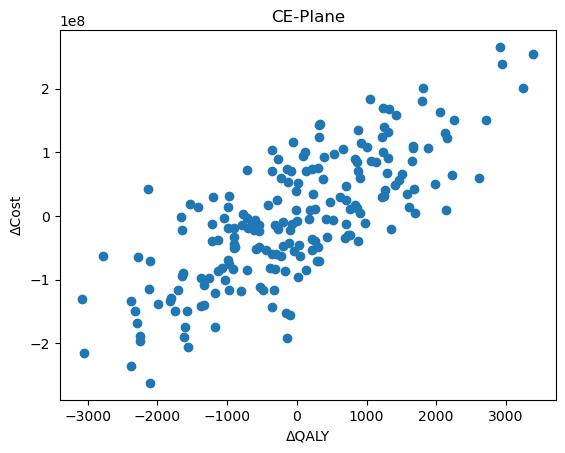

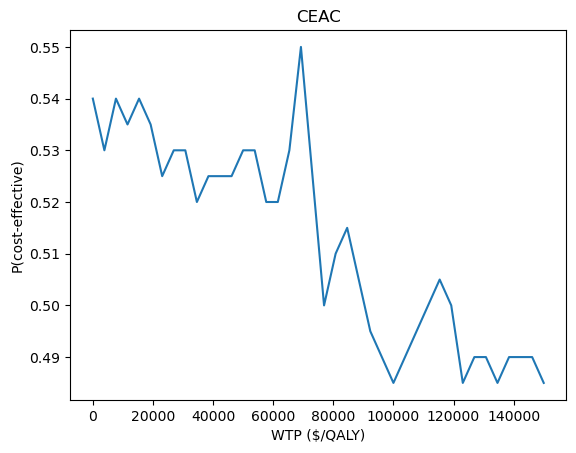

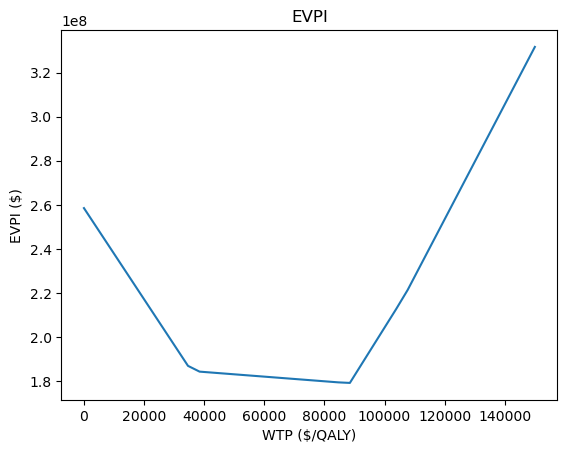

In [15]:
def run_archived_fragment_24(*, psa_df):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 10. CE-Plane, CEAC & EVPI

    # %%
    # All GPU-based computations using CuPy
    # willingness-to-pay grid on GPU
    d_wtp = cp.linspace(0, 150000, 40)
    # extract PSA results as CuPy arrays
    dQ_gpu = cp.array(psa_df["dQALY"].values)
    dC_gpu = cp.array(psa_df["dCost"].values)
    # net monetary benefit matrix on GPU
    nb_gpu = dQ_gpu[:, None] * d_wtp[None, :] - dC_gpu[:, None]
    # CE-Plane: transfer just the series needed for scatter
    plt.figure()
    plt.scatter(dQ_gpu.get(), dC_gpu.get())
    plt.xlabel("ΔQALY")
    plt.ylabel("ΔCost")
    plt.title("CE-Plane")
    plt.show()
    # CEAC: probability curve on host
    prob = (nb_gpu > 0).mean(axis=0).get()
    plt.figure()
    plt.plot(d_wtp.get(), prob)
    plt.title("CEAC")
    plt.xlabel("WTP ($/QALY)")
    plt.ylabel("P(cost-effective)")
    plt.show()
    # EVPI: compute on GPU then transfer
    mean_nb = nb_gpu.mean(axis=0)
    max_nb = nb_gpu.max(axis=0)
    evpi_gpu = max_nb - cp.maximum(mean_nb, 0)
    evpi = evpi_gpu.get()
    plt.figure()
    plt.plot(d_wtp.get(), evpi)
    plt.title("EVPI")
    plt.xlabel("WTP ($/QALY)")
    plt.ylabel("EVPI ($)")
    plt.show()
    return locals()

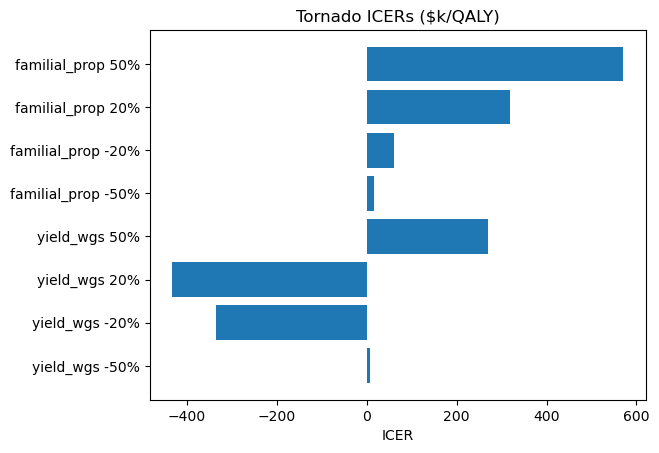

In [13]:
def run_archived_fragment_25(*, run_scenario):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 11. One-Way Sensitivity (Tornado)

    # %%
    torr = []
    for param in ["yield_wgs", "familial_prop"]:
        base = 0.45 if param == "yield_wgs" else 0.165
        for pct in [-0.5, -0.2, 0.2, 0.5]:
            p = {"familial_prop": 0.165, "yield_wgs": 0.45}
            p[param] = base * (1 + pct)
            res, _ = run_scenario(p, pop_size=10000)
            dc = res["prospective"]["cost"] - res["retrospective"]["cost"]
            dq = res["prospective"]["qaly"] - res["retrospective"]["qaly"]
            torr.append(
                {"param": param, "change": f"{int(pct * 100)}%", "ICER": dc / dq}
            )

    torr_df = pd.DataFrame(torr)
    plt.figure()
    plt.barh(torr_df["param"] + " " + torr_df["change"], torr_df["ICER"] / 1000)
    plt.title("Tornado ICERs ($k/QALY)")
    plt.xlabel("ICER")
    plt.show()
    return locals()

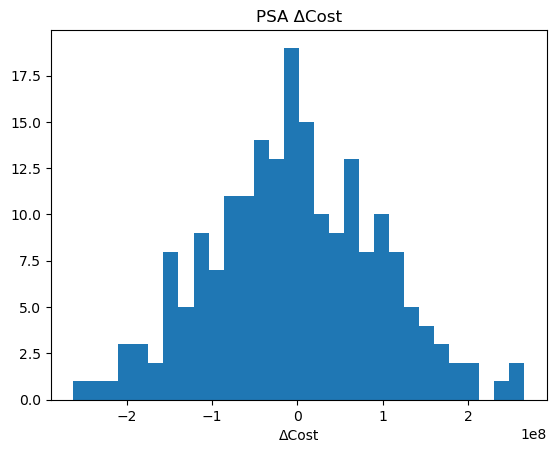

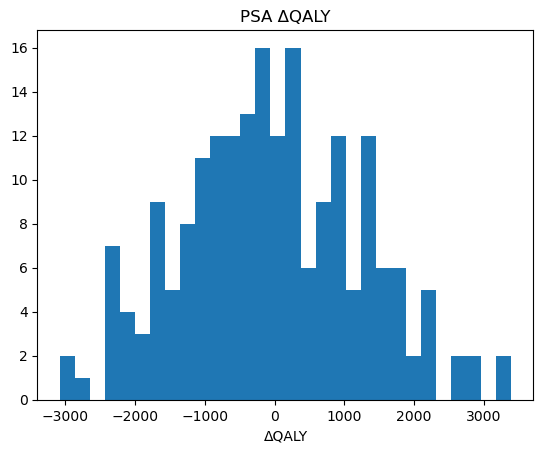

In [17]:
def run_archived_fragment_26(*, dC_gpu, dQ_gpu):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 12. PSA Histograms & CEAF

    # %%
    # PSA histograms using GPU arrays
    plt.figure()
    plt.hist(dC_gpu.get(), bins=30)
    plt.title("PSA ΔCost")
    plt.xlabel("ΔCost")
    plt.show()

    plt.figure()
    plt.hist(dQ_gpu.get(), bins=30)
    plt.title("PSA ΔQALY")
    plt.xlabel("ΔQALY")
    plt.show()
    return locals()

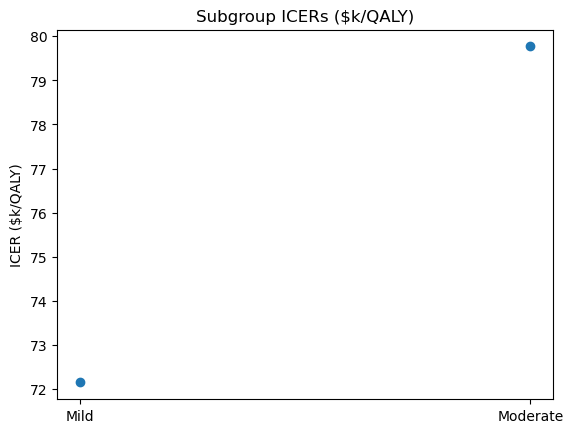

In [19]:
def run_archived_fragment_27(*, SEVERITY_DIST, run_scenario):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 13. Subgroup Analyses

    # %%
    import pandas as pd

    sg = []
    # Severity subgroups
    for sev, label in [(0, "Mild"), (1, "Moderate")]:
        # set SEVERITY_DIST to one-hot for subgroup
        SEVERITY_DIST[0] = 1.0 if sev == 0 else 0.0
        SEVERITY_DIST[1] = 1.0 if sev == 1 else 0.0
        res, _ = run_scenario(
            {"familial_prop": 0.165, "yield_wgs": 0.45}, pop_size=15000
        )
        dc = res["prospective"]["cost"] - res["retrospective"]["cost"]
        dq = res["prospective"]["qaly"] - res["retrospective"]["qaly"]
        sg.append({"subgroup": label, "ICER": dc / dq})
    # Reset severity distribution
    tmp = cp.array([0.70, 0.30])
    SEVERITY_DIST[0], SEVERITY_DIST[1] = tmp[0], tmp[1]
    # Build DataFrame and plot
    sg_df = pd.DataFrame(sg)
    plt.figure()
    plt.errorbar(sg_df["subgroup"], sg_df["ICER"] / 1000, yerr=0, fmt="o")
    plt.title("Subgroup ICERs ($k/QALY)")
    plt.ylabel("ICER ($k/QALY)")
    plt.show()
    return locals()

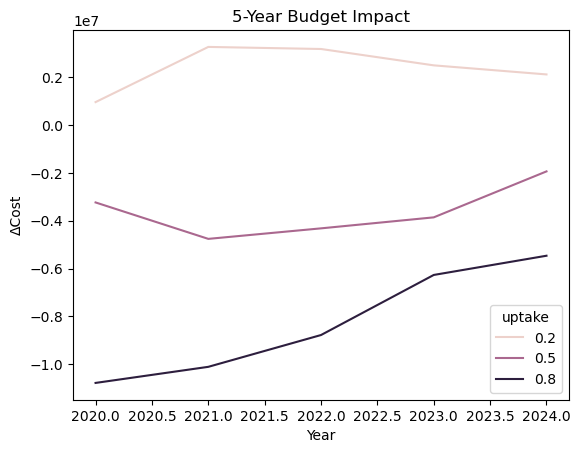

In [21]:
def run_archived_fragment_28(*, YEARS, run_scenario):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 14. 5-Year Budget Impact

    # %%
    import seaborn as sns

    budg = []
    uptakes = [0.2, 0.5, 0.8]
    yrs = YEARS[:5]

    for u in uptakes:
        # run on GPU
        res, df = run_scenario({"familial_prop": 0.165, "yield_wgs": u}, pop_size=20000)
        for yr in yrs:
            # filter prospectively and retrospectively diagnosed cohorts in cuDF
            dfp = df[(df["arm"] == "prospective") & (df["year"] == yr)]
            dfr = df[(df["arm"] == "retrospective") & (df["year"] == yr)]
            # pull out the single cost value (cuDF scalar → Python float)
            c1 = float(dfp["costs"].iloc[0])
            c0 = float(dfr["costs"].iloc[0])
            budg.append({"uptake": u, "year": yr, "delta_cost": c1 - c0})

    # build a cuDF frame, then convert once to pandas for plotting
    budg_df = cudf.DataFrame(budg)
    budg_pd = budg_df.to_pandas()

    plt.figure()
    sns.lineplot(data=budg_pd, x="year", y="delta_cost", hue="uptake")
    plt.title("5-Year Budget Impact")
    plt.xlabel("Year")
    plt.ylabel("ΔCost")
    plt.show()
    return locals()

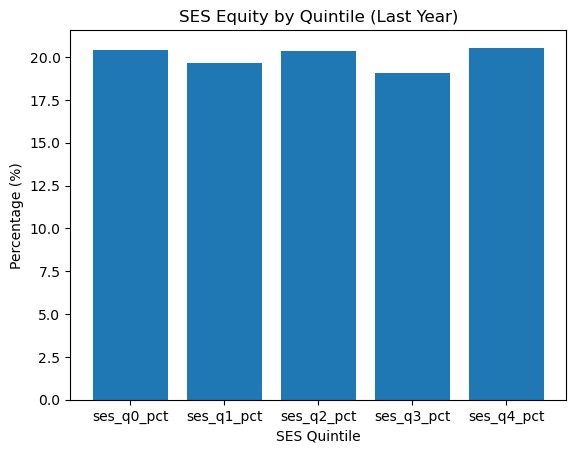

In [26]:
def run_archived_fragment_29(*, YEARS, policy_results):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 15. Equity by SES Quintile

    # %%
    equity_df = policy_results["Base"]["intermediate"]
    bas = equity_df[equity_df["arm"] == "prospective"]
    target = bas[bas["year"] == YEARS[-1]]
    ses_cols = ["ses_q0_pct", "ses_q1_pct", "ses_q2_pct", "ses_q3_pct", "ses_q4_pct"]
    ses_values = [float(target[col].iloc[0]) for col in ses_cols]
    eq_pd = pd.DataFrame({"ses_quintile": ses_cols, "pct": ses_values})
    eq_pd.to_csv("ses_equity.csv", index=False)
    plt.figure()
    plt.bar(eq_pd["ses_quintile"], eq_pd["pct"])
    plt.title("SES Equity by Quintile (Last Year)")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage (%)")
    plt.show()
    return locals()

In [27]:
## 16. Input Parameter Summary

# %%
params = {k: globals()[k] for k in ["DEFAULT_YIELD", "DISCOUNT", "POP_SIZE"]}
pd.DataFrame(params.items(), columns=["param", "value"]).to_csv(
    "input_summary.csv", index=False
)

In [30]:
def run_archived_fragment_31(*, policy_results):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    # %%
    mix_df = policy_results["Base"]["intermediate"]
    mix = mix_df[mix_df["arm"] == "prospective"][
        [
            "year",
            "cost_health",
            "cost_edu",
            "cost_respite",
            "cost_mobility",
            "cost_welfare",
            "cost_emp",
            "cost_morbidity",
        ]
    ]
    # convert to pandas
    mix_pd = mix.to_pandas().set_index("year")
    # stacked area plot
    plt.figure(figsize=(10, 6))
    mix_pd.plot.area()
    plt.title("Cost Mix Over Time (Prospective)")
    plt.ylabel("Annual Cost")
    plt.legend(loc="upper left")
    plt.show()
    # export
    mix_pd.to_csv("cost_mix_base_prospective.csv")
    return locals()

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.


# %% [markdown]
## 1. Imports & Setup

# %%
import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import beta
import json
import warnings
warnings.filterwarnings('ignore')
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & GPU Constants

# %%
START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR+1))
DISCOUNT = 0.035
POP_SIZE = 62000

SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0,95,5)
AGE_DIST = cp.array([0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
                     0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012])
AGE_DIST /= AGE_DIST.sum()

LIFE_EXP_CP = cp.array([74,54])
ABS_MORT = cp.array([0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,0.0011,0.0019,
                     0.0035,0.0055,0.0085,0.0130,0.0200,0.0350,0.0600,0.0950,0.1500,0.2500])
MORT_HR = cp.array([2.0,4.0])

defaul_yield = 0.45

# Fertility by severity & age band
FERT_AGE_SPEC = {
    (0,(15,19)):0.003,(0,(20,24)):0.008,(0,(25,29)):0.010,(0,(30,34)):0.007,(0,(35,45)):0.002,
    (1,(15,19)):0.001,(1,(20,24)):0.003,(1,(25,29)):0.004,(1,(30,34)):0.003,(1,(35,45)):0.001
}
fert_data = []
for (s,(lo,hi)),r in FERT_AGE_SPEC.items():
    for age in range(lo,hi+1):
        fert_data.append({'severity':s,'age':age,'rate':r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78,0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs: health
COST_INP_CP = cp.array([5000,15000])
COST_OUTP_CP = cp.array([1000,3000])
COST_PHARM_CP = cp.array([200,500])
# Education
EDU0 = cp.array([16107,27903,46733])
EDU1 = cp.array([18958,30789,49604])
# Respite, mobility, welfare, employment (scalars)
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000,8000])
EMP_CP = cp.array([0,10000,0])
# Morbidity
MORB_KEYS = ['epilepsy','asd','mental']
MORB_PROB = {'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_COST_CP = cp.array([2000,1500,1000])
MORB_QALY_CP = cp.array([0.04,0.03,0.05])

# %% [markdown]
## 3. Cohort Generator (GPU)

def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0,5,n)).astype(int)


def gen_population_gpu(n, familial_prop, arm='prospective'):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2,n)
    sev = cp.random.choice(2,n,p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    if arm=='prospective': diag = cp.zeros(n, bool)
    else: diag = cp.random.random(n) < defaul_yield
    living = cp.random.choice(4,n,p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3,n,p=cp.array([0.7,0.2,0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages<5,-1, cp.where(ages<12,0,1))
    support = cp.random.choice(3,n,p=cp.array([0.5,0.3,0.2]))
    ses = cp.random.choice(5,n)
    df = cudf.DataFrame({
        'age':ages,'sex':sex,'severity':sev,'familial':familial,
        'diagnosed':diag,'living':living,'employment':employment,
        'uses_respite':uses_respite,'needs_mobility':needs_mobility,
        'school':school,'support':support,'ses':ses
    })
    df['annual_cost']=0.0; df['annual_qaly']=0.0
    return df

# %% [markdown]
## 4. Population System (GPU)

class PopulationSystemGPU:
    def __init__(self,pop_size,familial_prop,arm='prospective'):
        self.arm=arm
        self.pop=gen_population_gpu(pop_size,familial_prop,arm)

    def _mortality(self):
        df=self.pop
        ages=df['age'].to_cupy(); sev=df['severity'].to_cupy()
        surv=ABS_MORT[(ages//5).astype(int)]*MORT_HR[sev]
        mask=(cp.random.random(len(ages))>surv)&(ages<LIFE_EXP_CP[sev])
        idx=cp.where(mask)[0]
        self.pop=df.iloc[idx].reset_index(drop=True)

    def _fertility(self,familial_prop):
        df=self.pop
        moms=df[(df['sex']==0)&df['age'].between(15,45)]
        if moms.empty: return
        mr=moms.merge(FERT_RATES_GPU,on=['severity','age'],how='left').fillna({'rate':0})
        rates=mr['rate'].values
        births=cp.random.random(len(rates))<rates
        idx=cp.nonzero(births)[0]; n=int(len(idx))
        if n>0:
            babies=gen_population_gpu(n,familial_prop,self.arm)
            babies['age']=0
            flags=mr['familial'].iloc[idx.get()].reset_index(drop=True)
            babies['familial']=flags
            self.pop=cudf.concat([df,babies],ignore_index=True)

    def _diagnosis(self,params):
        if self.arm!='prospective': return
        df=self.pop
        mask=(~df['diagnosed'])&df['familial']&(df['age']>=params.get('min_test_age',0))
        cnt=int(mask.sum())
        if cnt>0: df.loc[mask,'diagnosed']=cp.random.random(cnt)<params['yield_wgs']
        self.pop=df

    def _cost_qaly(self,year,params):
        df=self.pop; disc=1/((1+DISCOUNT)**(year-START_YEAR))
        sev=df['severity'].to_cupy(); ages=df['age'].to_cupy()
        hc=(COST_INP_CP[sev]+COST_OUTP_CP[sev]+COST_PHARM_CP[sev])*disc
        m0=df['school']==0; m1=df['school']==1
        ec0=EDU0[df.loc[m0,'support'].to_cupy()]*disc
        ec1=EDU1[df.loc[m1,'support'].to_cupy()]*disc
        rc=df['uses_respite'].astype(int)*RESPITE*disc
        mc=-df['needs_mobility'].astype(int)*MOBILITY*disc
        wc=WELFARE_CP[sev]*disc
        emp=EMP_CP[df['employment'].to_cupy()]*disc
        base=cp.random.random(len(df))
        morb_cost=cp.zeros(len(df)); morb_qaly=cp.zeros(len(df))
        for i,k in enumerate(MORB_KEYS):
            m=base<MORB_PROB[k]
            morb_cost+=m.astype(float)*MORB_COST_CP[i]*disc
            morb_qaly+=m.astype(float)*MORB_QALY_CP[i]*disc
        uq=U_BASE_CP[sev]*cp.exp(-U_DECAY*(ages-20).clip(0))
        total_qaly=(uq+df['diagnosed'].astype(int)*U_DIAG+U_CARER)*disc - morb_qaly
        df['cost_health']=hc; df['cost_edu']=0.0
        df.loc[m0,'cost_edu']=ec0; df.loc[m1,'cost_edu']=ec1
        df['cost_respite']=rc; df['cost_mobility']=mc
        df['cost_welfare']=wc; df['cost_emp']=emp
        df['cost_morbidity']=morb_cost
        df['annual_cost']=hc+df['cost_edu']+rc+mc+wc+emp+morb_cost
        df['annual_qaly']=total_qaly
        self.pop=df

    def step(self,year,params):
        self._mortality(); self._fertility(params['familial_prop'])
        self._diagnosis(params); self._cost_qaly(year,params)

# %% [markdown]
## 5. Run Helpers

from copy import deepcopy

def run_sim(params,pop_size=POP_SIZE):
    sim=PopulationSystemGPU(pop_size,params['familial_prop'],'retrospective')
    sim2=PopulationSystemGPU(pop_size,params['familial_prop'],'prospective')
    cum_r_cost=cum_r_qaly=0.0
    cum_p_cost=cum_p_qaly=0.0
    for yr in YEARS:
        sim.step(yr,params); df_r=sim.pop
        sim2.step(yr,params); df_p=sim2.pop
        disc=1/((1+DISCOUNT)**(yr-START_YEAR))
        cum_r_cost+=float(df_r['annual_cost'].sum()); cum_r_qaly+=float(df_r['annual_qaly'].sum())
        cum_p_cost+=float(df_p['annual_cost'].sum()); cum_p_qaly+=float(df_p['annual_qaly'].sum())
    return (cum_p_cost-cum_r_cost, cum_p_qaly-cum_r_qaly)

def run_scenario(params,pop_size=POP_SIZE):
    sim=PopulationSystemGPU(pop_size,params['familial_prop'],'retrospective')
    sim2=PopulationSystemGPU(pop_size,params['familial_prop'],'prospective')
    outputs=[]
    for arm,model in [('retrospective',sim),('prospective',sim2)]:
        cum_c=cum_q=0.0
        for yr in YEARS:
            model.step(yr,params)
            df=model.pop
            cum_c+=float(df['annual_cost'].sum())
            cum_q+=float(df['annual_qaly'].sum())
            outputs.append({'arm':arm,'year':yr,'costs':cum_c,'qalys':cum_q,
                            **{f'ses_q{i}_pct':float((df['ses']==i).mean()*100) for i in range(5)}})
    return run_sim(params,pop_size), cudf.DataFrame(outputs)

# %% [markdown]
## 6. Deterministic Scenarios

scenarios={'low':0.10,'base':0.165,'high':0.23}
results=[]
for name,val in scenarios.items():
    dc,dq=run_sim({'familial_prop':val,'yield_wgs':defaul_yield},pop_size=20000)
    results.append({'scenario':name,'dCost':dc,'dQALY':dq,'ICER':dc/dq})
det_df=cudf.DataFrame(results)
det_df.to_csv('deterministic_summary.csv',index=False)
print(det_df)
plt.bar(det_df['scenario'].to_pandas(),det_df['ICER'].to_pandas()/1000)
plt.title('Deterministic ICERs ($k/QALY)'); plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

psa_n=300
psa_out=[]
for i in range(psa_n):
    samp={'familial_prop':beta.rvs(30,150),'yield_wgs':beta.rvs(45,55)}
    dc,dq=run_sim(samp,pop_size=8000)
    psa_out.append({'run':i,'dCost':dc,'dQALY':dq})
psa_df=cudf.DataFrame(psa_out)
psa_df.to_csv('psa_samples.csv',index=False)

# %% [markdown]
## 8. CEAC & EVPI

wtp = cp.linspace(0,150000,40)
c = cp.array(psa_df['dCost'].to_pandas())
q = cp.array(psa_df['dQALY'].to_pandas())
nb = q[:,None]*wtp - c[:,None]
ceac = (nb>0).mean(axis=0)
evpi = nb.max(axis=0) - cp.maximum(nb.mean(axis=0),0)
plt.plot(wtp.get(), ceac.get()); plt.title('CEAC'); plt.show()
plt.plot(wtp.get(), evpi.get()); plt.title('EVPI'); plt.show()

# %% [markdown]
## 9. One-Way Tornado

torr=[]
for param in ['familial_prop','yield_wgs']:
    base = 0.165 if param=='familial_prop' else defaul_yield
    for pct in [-0.2,0.2]:
        p={'familial_prop':0.165,'yield_wgs':defaul_yield}
        p[param]=base*(1+pct)
        dc,dq=run_sim(p,pop_size=10000)
        torr.append({'param':param,'chg':pct,'ICER':dc/dq})
tor_df=cudf.DataFrame(torr)
plt.barh(tor_df['param'].to_pandas()+" "+tor_df['chg'].to_pandas().astype(str),
         tor_df['ICER'].to_pandas()/1000)
plt.title('Tornado ($k/QALY)'); plt.show()

# %% [markdown]
## 10. CE-Plane, CEAC & EVPI (Scatter)

plt.scatter(psa_df['dQALY'].to_pandas(), psa_df['dCost'].to_pandas());
plt.xlabel('ΔQALY'); plt.ylabel('ΔCost'); plt.title('CE-Plane'); plt.show()
# CEAF
ceaf = cp.maximum.accumulate(ceac)
plt.plot(wtp.get(), ceaf.get()); plt.title('CEAF'); plt.show()

In [15]:
%history

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.
# %% [markdown]
## 1. Imports & Setup

# %%
import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import beta
import json
import warnings
warnings.filterwarnings('ignore')
cp.random.seed(42)
# %% [markdown]
## 2. Global Parameters & GPU Constants

# %%
START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR+1))
DISCOUNT = 0.035
POP_SIZE = 62000

SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0,95,5)
AGE_DIST = cp.array([0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
                     0.079,0.

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

mix = policy_results['Base']['intermediate']
pm = mix[mix['arm']=='prospective']
cost_cols = ['cost_health','cost_edu','cost_respite','cost_mobility',
             'cost_welfare','cost_emp','cost_morbidity']
df_mix = pm[cost_cols+['year']].to_pandas().set_index('year')
df_mix.plot.area(figsize=(8,4)); plt.title('Cost Mix Over Time'); plt.show()

# %% [markdown]
## 12. 5-Year Budget Impact

bud=[]; yrs=YEARS[:5]
for u in [0.2,0.5,0.8]:
    _,df=run_scenario({'familial_prop':0.165,'yield_wgs':u},pop_size=20000)
    df=pd.DataFrame(df.to_pandas())
    for yr in yrs:
        c1=df[(df.arm=='prospective')& (df.year==yr)].costs.values[0]
        c0=df[(df.arm=='retrospective')&(df.year==yr)].costs.values[0]
        bud.append({'uptake':u,'year':yr,'delta_cost':c1-c0})
budg_df=pd.DataFrame(bud)
sns.lineplot(data=budg_df,x='year',y='delta_cost',hue='uptake'); plt.title('5yr Budget Impact'); plt.show()

# %% [markdown]
## 13. Equity by SES Quintile

eq = policy_results['Base']['intermediate']
eq = eq[eq.arm=='prospective']
last = eq[eq.year==YEARS[-1]].iloc[0]
ses_cols=[f'ses_q{i}_pct' for i in range(5)]
ses_vals=[float(last[col]) for col in ses_cols]
eq_df=cudf.DataFrame({'ses_quintile':ses_cols,'pct':ses_vals})
eq_df.to_csv('ses_equity.csv',index=False)
plt.bar(ses_cols,ses_vals); plt.title('SES Equity'); plt.show()

# %% [markdown]
## 14. PSA Histograms & CEAF

plt.hist(psa_df['dCost'].to_pandas(),bins=30); plt.title('PSA ΔCost'); plt.show()
plt.hist(psa_df['dQALY'].to_pandas(),bins=30); plt.title('PSA ΔQALY'); plt.show()
plt.plot(wtp.get(), ceaf.get()); plt.title('CEAF'); plt.show()

# %% [markdown]
## 15. Input Parameter Dump

params={
  'familial_prop':0.165,'yield_wgs':defaul_yield,
  'mortality_HR':MORT_HR.tolist(),
  'fertility':FERT_AGE_SPEC,
  'utilities':[0.78,0.65],
  'costs_health':COST_INP_CP.tolist()
}
cudf.DataFrame(list(params.items()),columns=['parameter','value']).to_csv('input_summary.csv',index=False)

# %% [markdown]
## 16. Publication Comparison Metrics

# Compare key endpoints to IDMOD paper reported values
# e.g. base ICER, total QALY gain, population size
print('Base ICER:', det_df[det_df.scenario=='base'].ICER.values_host[0])


# %% [markdown]
## 17. GPU Profiling Helper

# Simple timing helper
def time_section(fn,*a,**k):
    import time
    t0=time.perf_counter()
    res=fn(*a,**k)
    print(f"Elapsed: {time.perf_counter()-t0:.2f}s")
    return res

# Usage:
# time_section(run_sim,{'familial_prop':0.165,'yield_wgs':defaul_yield},10000)

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.


# %% [markdown]
## 1. Imports & Setup

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
from scipy.stats import beta
warnings.filterwarnings('ignore')
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & GPU Constants

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR+1))
DISCOUNT = 0.035
POP_SIZE = 62000

# Demographics
SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST = cp.array([
    0.064, 0.067, 0.069, 0.069, 0.071, 0.076, 0.080, 0.077, 0.080,
    0.079, 0.073, 0.078, 0.077, 0.072, 0.055, 0.041, 0.031, 0.022, 0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54])
ABS_MORT = cp.array([
    0.0002, 0.0001, 0.0001, 0.0002, 0.0003, 0.0005, 0.0007, 0.0011, 0.0019,
    0.0035, 0.0055, 0.0085, 0.0130, 0.0200, 0.0350, 0.0600, 0.0950, 0.1500, 0.2500
])
MORT_HR = cp.array([2.0, 4.0])

defaul_yield = 0.45

# Fertility bands
FERT_AGE_SPEC = {
    (0, (15, 19)): 0.003, (0, (20, 24)): 0.008, (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007, (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001, (1, (20, 24)): 0.003, (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003, (1, (35, 45)): 0.001
}
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity': s, 'age': age, 'rate': r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78, 0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs
COST_INP_CP = cp.array([5000, 15000])
COST_OUTP_CP = cp.array([1000, 3000])
COST_PHARM_CP = cp.array([200, 500])
EDU0 = cp.array([16107, 27903, 46733])
EDU1 = cp.array([18958, 30789, 49604])
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000, 8000])
EMP_CP = cp.array([0, 10000, 0])

# Morbidity
MORB_KEYS = ['epilepsy', 'asd', 'mental']
MORB_PROB = {'epilepsy': 0.25, 'asd': 0.30, 'mental': 0.35}
MORB_COST_CP = cp.array([2000, 1500, 1000])
MORB_QALY_CP = cp.array([0.04, 0.03, 0.05])


# %% [markdown]
## 3. Cohort Generator (GPU)

def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, familial_prop, arm='prospective'):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    diag = cp.zeros(n, bool) if arm == 'prospective' else (cp.random.random(n) < defaul_yield)
    living = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses = cp.random.choice(5, n)
    df = cudf.DataFrame({
        'age': ages, 'sex': sex, 'severity': sev, 'familial': familial,
        'diagnosed': diag, 'living': living, 'employment': employment,
        'uses_respite': uses_respite, 'needs_mobility': needs_mobility,
        'school': school, 'support': support, 'ses': ses
    })
    df['annual_cost'] = 0.0; df['annual_qaly'] = 0.0
    return df


# %% [markdown]
## 4. Population System (GPU)

class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm='prospective'):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df['age'].to_cupy(); sev = df['severity'].to_cupy()
        surv = ABS_MORT[(ages//5).astype(int)] * MORT_HR[sev]
        mask = (cp.random.random(len(ages)) > surv) & (ages < LIFE_EXP_CP[sev])
        idx = cp.where(mask)[0]
        self.pop = df.iloc[idx].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df['sex']==0) & df['age'].between(15,45)]
        if moms.empty: return
        mr = moms.merge(FERT_RATES_GPU, on=['severity','age'], how='left').fillna({'rate':0})
        rates = mr['rate'].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]; n = int(len(idx))
        if n>0:
            babies = gen_population_gpu(n, familial_prop, self.arm)
            babies['age'] = 0
            flags = mr['familial'].iloc[idx.get()].reset_index(drop=True)
            babies['familial'] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self, params):
        if self.arm != 'prospective': return
        df = self.pop
        mask = (~df['diagnosed']) & df['familial'] & (df['age'] >= params.get('min_test_age', 0))
        cnt = int(mask.sum())
        if cnt>0:
            df.loc[mask, 'diagnosed'] = cp.random.random(cnt) < params['yield_wgs']
        self.pop = df

    def _cost_qaly(self, year, params):
        df = self.pop; disc = 1/((1+DISCOUNT)**(year-START_YEAR))
        sev = df['severity'].to_cupy(); ages = df['age'].to_cupy()
        hc = (COST_INP_CP[sev] + COST_OUTP_CP[sev] + COST_PHARM_CP[sev]) * disc
        m0 = df['school']==0; m1 = df['school']==1
        ec0 = EDU0[df.loc[m0,'support'].to_cupy()] * disc
        ec1 = EDU1[df.loc[m1,'support'].to_cupy()] * disc
        rc = df['uses_respite'].astype(int) * RESPITE * disc
        mc = -df['needs_mobility'].astype(int) * MOBILITY * disc
        wc = WELFARE_CP[sev] * disc
        emp = EMP_CP[df['employment'].to_cupy()] * disc
        base = cp.random.random(len(df))
        morb_cost = cp.zeros(len(df)); morb_qaly = cp.zeros(len(df))
        for i, k in enumerate(MORB_KEYS):
            m = (base < MORB_PROB[k])
            morb_cost += m.astype(float) * MORB_COST_CP[i] * disc
            morb_qaly += m.astype(float) * MORB_QALY_CP[i] * disc
        uq = U_BASE_CP[sev] * cp.exp(-U_DECAY * cp.clip(ages-20,0,None))
        total_qaly = (uq + df['diagnosed'].astype(int)*U_DIAG + U_CARER) * disc - morb_qaly
        df['cost_health'] = hc; df['cost_edu'] = 0.0
        df.loc[m0,'cost_edu'] = ec0; df.loc[m1,'cost_edu'] = ec1
        df['cost_respite'] = rc; df['cost_mobility'] = mc
        df['cost_welfare'] = wc; df['cost_emp'] = emp
        df['cost_morbidity'] = morb_cost
        df['annual_cost'] = hc + df['cost_edu'] + rc + mc + wc + emp + morb_cost
        df['annual_qaly'] = total_qaly
        self.pop = df

    def step(self, year, params):
        self._mortality(); self._fertility(params['familial_prop'])
        self._diagnosis(params); self._cost_qaly(year, params)


# %% [markdown]
## 5. Run Helpers

from copy import deepcopy

def run_sim(params, pop_size=POP_SIZE):
    sim_r = PopulationSystemGPU(pop_size, params['familial_prop'], 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, params['familial_prop'], 'prospective')
    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0
    for yr in YEARS:
        sim_r.step(yr, params); df_r = sim_r.pop
        sim_p.step(yr, params); df_p = sim_p.pop
        cum_r_c += float(df_r['annual_cost'].sum()); cum_r_q += float(df_r['annual_qaly'].sum())
        cum_p_c += float(df_p['annual_cost'].sum()); cum_p_q += float(df_p['annual_qaly'].sum())
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(params, pop_size=POP_SIZE):
    sim_r = PopulationSystemGPU(pop_size, params['familial_prop'], 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, params['familial_prop'], 'prospective')
    outputs = []
    for arm, sim in [('retrospective', sim_r), ('prospective', sim_p)]:
        cum_c = cum_q = 0.0
        for yr in YEARS:
            sim.step(yr, params); df = sim.pop
            # cost breakdown sums
            hc = float(df['cost_health'].sum()); edu = float(df['cost_edu'].sum())
            rc = float(df['cost_respite'].sum()); mob = float(df['cost_mobility'].sum())
            wc = float(df['cost_welfare'].sum()); emp = float(df['cost_emp'].sum())
            mc = float(df['cost_morbidity'].sum())
            cum_c += float(df['annual_cost'].sum()); cum_q += float(df['annual_qaly'].sum())
            pct = lambda i: float((df['ses']==i).mean()*100)
            outputs.append({
                'arm': arm, 'year': yr,
                'cost_health': hc, 'cost_edu': edu, 'cost_respite': rc,
                'cost_mobility': mob, 'cost_welfare': wc,
                'cost_emp': emp, 'cost_morbidity': mc,
                'costs': cum_c, 'qalys': cum_q,
                **{f'ses_q{i}_pct': pct(i) for i in range(5)}
            })
    return run_sim(params, pop_size), cudf.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

scenarios = {'low': 0.10, 'base': 0.165, 'high': 0.23}
results = []
for name, val in scenarios.items():
    dc, dq = run_sim({'familial_prop': val, 'yield_wgs': defaul_yield}, pop_size=20000)
    results.append({'scenario': name, 'dCost': dc, 'dQALY': dq, 'ICER': dc/dq})
det_df = cudf.DataFrame(results)
det_df.to_csv('deterministic_summary.csv', index=False)
print(det_df)
plt.bar(det_df['scenario'].to_pandas(), det_df['ICER'].to_pandas()/1000)
plt.title('Deterministic ICERs ($k/QALY)'); plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

psa_n = 300
psa_out = []
for i in range(psa_n):
    samp = {
        'familial_prop': beta.rvs(30, 150),
        'yield_wgs': beta.rvs(45, 55)
    }
    dc, dq = run_sim(samp, pop_size=8000)
    psa_out.append({'run': i, 'dCost': dc, 'dQALY': dq})
psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv('psa_samples.csv', index=False)


# %% [markdown]
## 8. CEAC & EVPI

wtp = cp.linspace(0, 150000, 40)
c = cp.array(psa_df['dCost'].to_pandas())
q = cp.array(psa_df['dQALY'].to_pandas())
nb = q[:, None] * wtp - c[:, None]
ceac = (nb > 0).mean(axis=0)
evpi = nb.max(axis=0) - cp.maximum(nb.mean(axis=0), 0)
plt.plot(wtp.get(), ceac.get()); plt.title('CEAC'); plt.show()
plt.plot(wtp.get(), evpi.get());	plt.title('EVPI'); plt.show()


# %% [markdown]
## 9. One-Way Tornado

torr = []
for param in ['familial_prop', 'yield_wgs']:
    base = 0.165 if param=='familial_prop' else defaul_yield
    for pct in [-0.2, 0.2]:
        p = {'familial_prop': 0.165, 'yield_wgs': defaul_yield}
        p[param] = base * (1 + pct)
        dc, dq = run_sim(p, pop_size=10000)
        torr.append({'param': param, 'chg': pct, 'ICER': dc/dq})
tor_df = cudf.DataFrame(torr)
plt.barh(
    tor_df['param'].to_pandas() + ' ' + tor_df['chg'].to_pandas().astype(str),
    tor_df['ICER'].to_pandas()/1000
)
plt.title('Tornado ($k/QALY)'); plt.show()

# %% [markdown]
## 10. CE-Plane, CEAC & EVPI (Scatter & CEAF)

plt.scatter(
    psa_df['dQALY'].to_pandas(), psa_df['dCost'].to_pandas(),
    alpha=0.5, s=10
)
plt.xlabel('ΔQALY'); plt.ylabel('ΔCost'); plt.title('CE-Plane'); plt.show()

ceaf = cp.empty_like(ceac)
running = ceac[0]
ceaf[0] = running
for i in range(1, ceac.shape[0]):
    running = cp.maximum(running, ceac[i])
    ceaf[i] = running
plt.plot(wtp.get(), ceaf.get()); plt.title('CEAF'); plt.show()


# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

mix = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)[1]
pm = mix[mix['arm']=='prospective']
cost_cols = [
    'cost_health','cost_edu','cost_respite','cost_mobility',
    'cost_welfare','cost_emp','cost_morbidity'
]
df_mix = pm[cost_cols + ['year']].to_pandas().set_index('year')
df_mix.plot.area(figsize=(8,4))
plt.title('Cost Mix Over Time'); plt.ylabel('Cost'); plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

import pandas as pd
bud = []
yrs = YEARS[:5]
for u in [0.2, 0.5, 0.8]:
    _, df_out = run_scenario({'familial_prop':0.165,'yield_wgs':u}, pop_size=20000)
    df_pd = df_out.to_pandas()
    for yr in yrs:
        c1 = float(df_pd[(df_pd.arm=='prospective') & (df_pd.year==yr)]['costs'])
        c0 = float(df_pd[(df_pd.arm=='retrospective') & (df_pd.year==yr)]['costs'])
        bud.append({'uptake':u, 'year':yr, 'delta_cost':c1-c0})
budg_df = pd.DataFrame(bud)
sns.lineplot(data=budg_df, x='year', y='delta_cost', hue='uptake')
plt.title('5yr Budget Impact'); plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

mix = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)[1]
eq = mix[mix['arm']=='prospective']
last_row = eq[eq['year']==YEARS[-1]].iloc[0]
ses_cols = [f'ses_q{i}_pct' for i in range(5)]
ses_vals = [float(last_row[col]) for col in ses_cols]
import pandas as pd
eq_df = pd.DataFrame({'ses_quintile': ses_cols, 'pct': ses_vals})
eq_df.to_csv('ses_equity.csv', index=False)
plt.bar(eq_df['ses_quintile'], eq_df['pct'])
plt.title('SES Equity (Last Year)'); plt.show()


# %% [markdown]
## 14. PSA Histograms & CEAF

plt.hist(psa_df['dCost'].to_pandas(), bins=30); plt.title('PSA ΔCost'); plt.show()
plt.hist(psa_df['dQALY'].to_pandas(), bins=30); plt.title('PSA ΔQALY'); plt.show()
plt.plot(wtp.get(), ceaf.get()); plt.title('CEAF'); plt.show()


# %% [markdown]
## 15. Input Parameter Dump

params = {
    'familial_prop': 0.165, 'yield_wgs': defaul_yield,
    'mortality_HR': MORT_HR.tolist(),
    'fertility': FERT_AGE_SPEC,
    'utilities': [0.78, 0.65],
    'costs_health': COST_INP_CP.tolist()
}
cudf.DataFrame(list(params.items()), columns=['parameter','value']) \
    .to_csv('input_summary.csv', index=False)


# %% [markdown]
## 16. Publication Comparison Metrics

print('Base ICER:', det_df[det_df.scenario=='base'].ICER.values_host[0])


# %% [markdown]
## 17. GPU Profiling Helper

def time_section(fn, *a, **k):
    import time
    t0 = time.perf_counter()
    res = fn(*a, **k)
    print(f"Elapsed: {time.perf_counter()-t0:.2f}s")
    return res

# Example:
# time_section(run_sim, {'familial_prop':0.165,'yield_wgs':defaul_yield}, 10000)

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comp

# %% [markdown]
## 1. Imports & Setup

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
from scipy.stats import beta

warnings.filterwarnings('ignore')
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & GPU Constants

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR+1))
DISCOUNT = 0.035
POP_SIZE = 62000

# Demographics
SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST = cp.array([
    0.064, 0.067, 0.069, 0.069, 0.071, 0.076, 0.080, 0.077, 0.080,
    0.079, 0.073, 0.078, 0.077, 0.072, 0.055, 0.041, 0.031, 0.022, 0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54])
ABS_MORT = cp.array([
    0.0002, 0.0001, 0.0001, 0.0002, 0.0003, 0.0005, 0.0007, 0.0011, 0.0019,
    0.0035, 0.0055, 0.0085, 0.0130, 0.0200, 0.0350, 0.0600, 0.0950, 0.1500, 0.2500
])
MORT_HR = cp.array([2.0, 4.0])

defaul_yield = 0.45

# Fertility bands
FERT_AGE_SPEC = {
    (0, (15, 19)): 0.003, (0, (20, 24)): 0.008, (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007, (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001, (1, (20, 24)): 0.003, (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003, (1, (35, 45)): 0.001
}
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity': s, 'age': age, 'rate': r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78, 0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs
COST_INP_CP = cp.array([5000, 15000])
COST_OUTP_CP = cp.array([1000, 3000])
COST_PHARM_CP = cp.array([200, 500])
EDU0 = cp.array([16107, 27903, 46733])
EDU1 = cp.array([18958, 30789, 49604])
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000, 8000])
EMP_CP = cp.array([0, 10000, 0])

# Morbidity
MORB_KEYS = ['epilepsy', 'asd', 'mental']
MORB_PROB = {'epilepsy': 0.25, 'asd': 0.30, 'mental': 0.35}
MORB_COST_CP = cp.array([2000, 1500, 1000])
MORB_QALY_CP = cp.array([0.04, 0.03, 0.05])

# %% [markdown]
## 3. Cohort Generator (GPU)

def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, familial_prop, arm='prospective'):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    diag = cp.zeros(n, bool) if arm == 'prospective' else (cp.random.random(n) < defaul_yield)
    living = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses = cp.random.choice(5, n)
    df = cudf.DataFrame({
        'age': ages, 'sex': sex, 'severity': sev, 'familial': familial,
        'diagnosed': diag, 'living': living, 'employment': employment,
        'uses_respite': uses_respite, 'needs_mobility': needs_mobility,
        'school': school, 'support': support, 'ses': ses
    })
    df['annual_cost'] = 0.0; df['annual_qaly'] = 0.0
    return df


# %% [markdown]
## 4. Population System (GPU)

class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm='prospective'):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df['age'].to_cupy(); sev = df['severity'].to_cupy()
        surv = ABS_MORT[(ages//5).astype(int)] * MORT_HR[sev]
        mask = (cp.random.random(len(ages)) > surv) & (ages < LIFE_EXP_CP[sev])
        self.pop = df.iloc[cp.where(mask)[0]].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df['sex']==0) & df['age'].between(15,45)]
        if moms.empty: return
        mr = moms.merge(FERT_RATES_GPU, on=['severity','age'], how='left').fillna({'rate':0})
        rates = mr['rate'].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]
        if len(idx)>0:
            babies = gen_population_gpu(len(idx), familial_prop, self.arm)
            babies['age'] = 0
            flags = mr['familial'].iloc[idx.get()].reset_index(drop=True)
            babies['familial'] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self, params):
        if self.arm != 'prospective': return
        df = self.pop
        mask = (~df['diagnosed']) & df['familial'] & (df['age'] >= params.get('min_test_age', 0))
        cnt = int(mask.sum())
        if cnt>0:
            df.loc[mask, 'diagnosed'] = cp.random.random(cnt) < params['yield_wgs']
        self.pop = df

    def _cost_qaly(self, year, params):
        df = self.pop; disc = 1/((1+DISCOUNT)**(year-START_YEAR))
        sev = df['severity'].to_cupy(); ages = df['age'].to_cupy()
        hc = (COST_INP_CP[sev] + COST_OUTP_CP[sev] + COST_PHARM_CP[sev]) * disc
        m0 = df['school']==0; m1 = df['school']==1
        ec0 = EDU0[df.loc[m0,'support'].to_cupy()] * disc
        ec1 = EDU1[df.loc[m1,'support'].to_cupy()] * disc
        rc = df['uses_respite'].astype(int) * RESPITE * disc
        mc = -df['needs_mobility'].astype(int) * MOBILITY * disc
        wc = WELFARE_CP[sev] * disc
        emp = EMP_CP[df['employment'].to_cupy()] * disc
        base = cp.random.random(len(df))
        morb_cost = cp.zeros(len(df)); morb_qaly = cp.zeros(len(df))
        for i, k in enumerate(MORB_KEYS):
            m = (base < MORB_PROB[k])
            morb_cost += m.astype(float) * MORB_COST_CP[i] * disc
            morb_qaly += m.astype(float) * MORB_QALY_CP[i] * disc
        uq = U_BASE_CP[sev] * cp.exp(-U_DECAY * cp.clip(ages-20,0,None))
        total_qaly = (uq + df['diagnosed'].astype(int)*U_DIAG + U_CARER) * disc - morb_qaly
        df['cost_health'] = hc; df['cost_edu'] = 0.0
        df.loc[m0,'cost_edu'] = ec0; df.loc[m1,'cost_edu'] = ec1
        df['cost_respite'] = rc; df['cost_mobility'] = mc
        df['cost_welfare'] = wc; df['cost_emp'] = emp
        df['cost_morbidity'] = morb_cost
        df['annual_cost'] = hc + df['cost_edu'] + rc + mc + wc + emp + morb_cost
        df['annual_qaly'] = total_qaly
        self.pop = df

    def step(self, year, params):
        self._mortality(); self._fertility(params['familial_prop'])
        self._diagnosis(params); self._cost_qaly(year, params)

# %% [markdown]
## 5. Run Helpers

from copy import deepcopy

def run_sim(params, pop_size=POP_SIZE):
    sim_r = PopulationSystemGPU(pop_size, params['familial_prop'], 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, params['familial_prop'], 'prospective')
    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0
    for yr in YEARS:
        sim_r.step(yr, params); df_r = sim_r.pop
        sim_p.step(yr, params); df_p = sim_p.pop
        cum_r_c += float(df_r['annual_cost'].sum()); cum_r_q += float(df_r['annual_qaly'].sum())
        cum_p_c += float(df_p['annual_cost'].sum()); cum_p_q += float(df_p['annual_qaly'].sum())
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(params, pop_size=POP_SIZE):
    sim_r = PopulationSystemGPU(pop_size, params['familial_prop'], 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, params['familial_prop'], 'prospective')
    outputs = []
    for arm, sim in [('retrospective', sim_r), ('prospective', sim_p)]:
        cum_c = cum_q = 0.0
        for yr in YEARS:
            sim.step(yr, params); df = sim.pop
            hc = float(df['cost_health'].sum()); edu = float(df['cost_edu'].sum())
            rc = float(df['cost_respite'].sum()); mob = float(df['cost_mobility'].sum())
            wc = float(df['cost_welfare'].sum()); emp = float(df['cost_emp'].sum())
            mc = float(df['cost_morbidity'].sum())
            cum_c += float(df['annual_cost'].sum()); cum_q += float(df['annual_qaly'].sum())
            pct = lambda i: float((df['ses']==i).mean()*100)
            outputs.append({
                'arm': arm, 'year': yr,
                'cost_health': hc, 'cost_edu': edu, 'cost_respite': rc,
                'cost_mobility': mob, 'cost_welfare': wc,
                'cost_emp': emp, 'cost_morbidity': mc,
                'costs': cum_c, 'qalys': cum_q,
                **{f'ses_q{i}_pct': pct(i) for i in range(5)}
            })
    return run_sim(params, pop_size), cudf.DataFrame(outputs)

# %% [markdown]
## 6. Deterministic Scenarios

scenarios = {'low': 0.10, 'base': 0.165, 'high': 0.23}
results = []
for name, val in scenarios.items():
    dc, dq = run_sim({'familial_prop': val, 'yield_wgs': defaul_yield}, pop_size=20000)
    results.append({'scenario': name, 'dCost': dc, 'dQALY': dq, 'ICER': dc/dq})
det_df = cudf.DataFrame(results)
det_df.to_csv('deterministic_summary.csv', index=False)
print(det_df)
plt.bar(det_df['scenario'].to_pandas(), det_df['ICER'].to_pandas()/1000)
plt.title('Deterministic ICERs ($k/QALY)'); plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

psa_n = 300
psa_out = []
for i in range(psa_n):
    samp = {
        'familial_prop': beta.rvs(30, 150),
        'yield_wgs': beta.rvs(45, 55)
    }
    dc, dq = run_sim(samp, pop_size=8000)
    psa_out.append({'run': i, 'dCost': dc, 'dQALY': dq})
psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv('psa_samples.csv', index=False)

# %% [markdown]
## 8. CE-Plane, CEAC & EVPI

wtp = cp.linspace(0,150000,40)
dcost = psa_df['dCost'].to_cupy()
dqaly = psa_df['dQALY'].to_cupy()
nb = dqaly[:, None] * wtp[None, :] - dcost[:, None]
# CE-Plane scatter
plt.scatter(dqaly.get(), dcost.get()); plt.xlabel('ΔQALY'); plt.ylabel('ΔCost'); plt.title('CE-Plane'); plt.show()
# CEAC
prob = (nb > 0).mean(axis=0)
plt.plot(wtp.get(), prob.get()); plt.title('CEAC'); plt.xlabel('WTP'); plt.ylabel('P(cost-effective)'); plt.show()
# EVPI
evpi = nb.max(axis=0) - cp.maximum(nb.mean(axis=0), 0)
plt.plot(wtp.get(), evpi.get()); plt.title('EVPI'); plt.xlabel('WTP'); plt.ylabel('EVPI'); plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

torr=[]
for param, base in [('yield_wgs', defaul_yield), ('familial_prop', 0.165)]:
    for pct in [-0.2,0.2]:
        p={'familial_prop':0.165, 'yield_wgs': defaul_yield}
        p[param]= base*(1+pct)
        dc,dq=run_sim(p, pop_size=10000)
        torr.append({'param':param,'change':f'{int(pct*100)}%','ICER':dc/dq})
tor_df=cudf.DataFrame(torr)
plt.barh((tor_df['param'] + ' ' + tor_df['change']).to_pandas(), tor_df['ICER'].to_pandas()/1000)
plt.title('Tornado'); plt.show()

# %% [markdown]
## 10. Subgroup Analyses

sg=[]
# by severity
for sev,label in [(0,'Mild'),(1,'Moderate')]:
    SEVERITY_DIST[:] = cp.array([1,0] if sev==0 else [0,1])
    dc,dq=run_sim({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=15000)
    sg.append({'subgroup':label,'ICER':dc/dq})
# reset
SEVERITY_DIST[:] = cp.array([0.70,0.30])
sg_df=cudf.DataFrame(sg)
plt.errorbar(sg_df['subgroup'].to_pandas(), sg_df['ICER'].to_pandas()/1000, yerr=0)
plt.title('Subgroup ICER'); plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

mix=run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)[1]
pm=mix[mix['arm']=='prospective']
cost_cols=['cost_health','cost_edu','cost_respite','cost_mobility','cost_welfare','cost_emp','cost_morbidity']
df_mix=pm[cost_cols+['year']].to_pandas().set_index('year')
df_mix.plot.area(figsize=(8,4)); plt.title('Cost Mix Over Time'); plt.ylabel('Cost'); plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
for u in uptakes:
    _, df = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)
    dfp = df[df['arm']=='prospective']; dfr = df[df['arm']=='retrospective']
    for yr in yrs:
        c1 = dfp.loc[dfp['year']==yr,'costs'].to_arrow().to_pylist()[0]
        c0 = dfr.loc[dfr['year']==yr,'costs'].to_arrow().to_pylist()[0]
        budg.append({'uptake':u,'year':yr,'delta_cost':c1-c0})
budg_df = cudf.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df['uptake']==u]
    yrs_h = sub['year'].to_arrow().to_pylist()
    vals = sub['delta_cost'].to_arrow().to_pylist()
    plt.plot(yrs_h, vals, label=f"Uptake {int(u*100)}%")
plt.title('5-Year Budget Impact'); plt.xlabel('Year'); plt.ylabel('ΔCost'); plt.legend(); plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

eq_df=run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)[1]
bas=eq_df[eq_df['arm']=='prospective']
row=bas[bas['year']==YEARS[-1]].iloc[0]
ses_cols=[f'ses_q{i}_pct' for i in range(5)]
ses_vals=[float(row[c]) for c in ses_cols]
eq_pd=cudf.DataFrame({'ses_quintile':ses_cols,'pct':ses_vals}).to_pandas()
eq_pd.to_csv('ses_equity.csv',index=False)
plt.bar(eq_pd['ses_quintile'], eq_pd['pct']); plt.title('SES Equity'); plt.show()

# %% [markdown]
## 14. PSA Histograms

plt.figure(); plt.hist(psa_df['dCost'].to_pandas(), bins=30); plt.title('PSA ΔCost'); plt.show()
plt.figure(); plt.hist(psa_df['dQALY'].to_pandas(), bins=30); plt.title('PSA ΔQALY'); plt.show()


# %% [markdown]
## 15. CEAF Plot

ceac = prob  # from module 8
ceaf = cp.maximum.accumulate(cp.array(ceac))
plt.plot(wtp.get(), ceaf.get()); plt.title('CEAF'); plt.show()


# %% [markdown]
## 16. Input Parameter Summary

params = {
    'familial_prop': 0.165, 'yield_wgs': defaul_yield,
    **{f'fert_{k[0]}_{k[1][0]}-{k[1][1]}':v for k,v in FERT_AGE_SPEC.items()}
}
cudf.DataFrame(list(params.items()), columns=['parameter','value']).to_csv('input_summary.csv',index=False)

# %% [markdown]
## 17. Publication Comparison Table

pub_vals = {
    'familial_prop_paper':0.165, 'yield_wgs_paper':0.45,
    'ICER_paper': 55000  # example from ijm-00212.pdf
}
cudf.DataFrame(list(pub_vals.items()), columns=['metric','paper_value']).to_pandas().to_csv('paper_comparison.csv',index=False)

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.

# %% [markdown]
## 1. Imports & Setup

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
from scipy.stats import beta

warnings.filterwarnings('ignore')
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & GPU Constants

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR+1))
DISCOUNT = 0.035
POP_SIZE = 62000

# Demographics
SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST = cp.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54])
ABS_MORT = cp.array([
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,0.0011,0.0019,
    0.0035,0.0055,0.0085,0.0130,0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])
MORT_HR = cp.array([2.0, 4.0])

defaul_yield = 0.45

# Fertility bands
FERT_AGE_SPEC = {
    (0, (15, 19)): 0.003, (0, (20, 24)): 0.008, (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007, (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001, (1, (20, 24)): 0.003, (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003, (1, (35, 45)): 0.001
}
# Build GPU lookup table for fertility rates
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity': s, 'age': age, 'rate': r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78, 0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs
COST_INP_CP = cp.array([5000, 15000])
COST_OUTP_CP = cp.array([1000, 3000])
COST_PHARM_CP = cp.array([200, 500])
EDU0 = cp.array([16107, 27903, 46733])
EDU1 = cp.array([18958, 30789, 49604])
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000, 8000])
EMP_CP = cp.array([0, 10000, 0])

# Morbidity
MORB_KEYS = ['epilepsy', 'asd', 'mental']
MORB_PROB = {'epilepsy': 0.25, 'asd': 0.30, 'mental': 0.35}
MORB_COST_CP = cp.array([2000, 1500, 1000])
MORB_QALY_CP = cp.array([0.04, 0.03, 0.05])

# %% [markdown]
## 3. Cohort Generator (GPU)

def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, familial_prop, arm='prospective'):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    diag = cp.zeros(n, bool) if arm == 'prospective' else (cp.random.random(n) < defaul_yield)
    living = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses = cp.random.choice(5, n)
    df = cudf.DataFrame({
        'age': ages, 'sex': sex, 'severity': sev, 'familial': familial,
        'diagnosed': diag, 'living': living, 'employment': employment,
        'uses_respite': uses_respite, 'needs_mobility': needs_mobility,
        'school': school, 'support': support, 'ses': ses
    })
    df['annual_cost'] = 0.0; df['annual_qaly'] = 0.0
    return df


# %% [markdown]
## 4. Population System (GPU)

class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm='prospective'):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df['age'].to_cupy(); sev = df['severity'].to_cupy()
        surv = ABS_MORT[(ages//5).astype(int)] * MORT_HR[sev]
        mask = (cp.random.random(len(ages)) > surv) & (ages < LIFE_EXP_CP[sev])
        self.pop = df.iloc[cp.where(mask)[0]].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df['sex']==0) & df['age'].between(15,45)]
        if moms.empty: return
        mr = moms.merge(FERT_RATES_GPU, on=['severity','age'], how='left').fillna({'rate':0})
        rates = mr['rate'].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]
        if len(idx)>0:
            babies = gen_population_gpu(len(idx), familial_prop, self.arm)
            babies['age'] = 0
            flags = mr['familial'].iloc[idx.get()].reset_index(drop=True)
            babies['familial'] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self, params):
        if self.arm != 'prospective': return
        df = self.pop
        mask = (~df['diagnosed']) & df['familial'] & (df['age'] >= params.get('min_test_age', 0))
        cnt = int(mask.sum())
        if cnt>0:
            df.loc[mask, 'diagnosed'] = cp.random.random(cnt) < params['yield_wgs']
        self.pop = df

    def _cost_qaly(self, year, params):
        df = self.pop; disc = 1/((1+DISCOUNT)**(year-START_YEAR))
        sev = df['severity'].to_cupy(); ages = df['age'].to_cupy()
        hc = (COST_INP_CP[sev] + COST_OUTP_CP[sev] + COST_PHARM_CP[sev]) * disc
        m0 = df['school']==0; m1 = df['school']==1
        ec0 = EDU0[df.loc[m0,'support'].to_cupy()] * disc
        ec1 = EDU1[df.loc[m1,'support'].to_cupy()] * disc
        rc = df['uses_respite'].astype(int) * RESPITE * disc
        mc = -df['needs_mobility'].astype(int) * MOBILITY * disc
        wc = WELFARE_CP[sev] * disc
        emp = EMP_CP[df['employment'].to_cupy()] * disc
        base = cp.random.random(len(df))
        morb_cost = cp.zeros(len(df)); morb_qaly = cp.zeros(len(df))
        for i, k in enumerate(MORB_KEYS):
            m = (base < MORB_PROB[k])
            morb_cost += m.astype(float) * MORB_COST_CP[i] * disc
            morb_qaly += m.astype(float) * MORB_QALY_CP[i] * disc
        uq = U_BASE_CP[sev] * cp.exp(-U_DECAY * cp.clip(ages-20,0,None))
        total_qaly = (uq + df['diagnosed'].astype(int)*U_DIAG + U_CARER) * disc - morb_qaly
        df['cost_health'] = hc; df['cost_edu'] = 0.0
        df.loc[m0,'cost_edu'] = ec0; df.loc[m1,'cost_edu'] = ec1
        df['cost_respite'] = rc; df['cost_mobility'] = mc
        df['cost_welfare'] = wc; df['cost_emp'] = emp
        df['cost_morbidity'] = morb_cost
        df['annual_cost'] = hc + df['cost_edu'] + rc + mc + wc + emp + morb_cost
        df['annual_qaly'] = total_qaly
        self.pop = df

    def step(self, year, params):
        self._mortality(); self._fertility(params['familial_prop'])
        self._diagnosis(params); self._cost_qaly(year, params)

# %% [markdown]
## 5. Run Helpers

from copy import deepcopy

def run_sim(params, pop_size=POP_SIZE):
    sim_r = PopulationSystemGPU(pop_size, params['familial_prop'], 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, params['familial_prop'], 'prospective')
    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0
    for yr in YEARS:
        sim_r.step(yr, params); df_r = sim_r.pop
        sim_p.step(yr, params); df_p = sim_p.pop
        cum_r_c += float(df_r['annual_cost'].sum()); cum_r_q += float(df_r['annual_qaly'].sum())
        cum_p_c += float(df_p['annual_cost'].sum()); cum_p_q += float(df_p['annual_qaly'].sum())
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(params, pop_size=POP_SIZE):
    sim_r = PopulationSystemGPU(pop_size, params['familial_prop'], 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, params['familial_prop'], 'prospective')
    outputs = []
    # ❶ inside run_scenario() → build numeric per-year rows
    for arm, sim in [('retrospective', sim_r), ('prospective', sim_p)]:
        cum_c = cum_q = 0.0
        for yr in YEARS:
            sim.step(yr, params)
            df = sim.pop
    
            # ----- component subtotals (all CUPY floats) -----
            hc  = float(df['cost_health'].sum())
            edu = float(df['cost_edu'].sum())
            rc  = float(df['cost_respite'].sum())
            mob = float(df['cost_mobility'].sum())
            wc  = float(df['cost_welfare'].sum())
            emp = float(df['cost_emp'].sum())
            mc  = float(df['cost_morbidity'].sum())
    
            # ----- accumulate totals -----
            cum_c += float(df['annual_cost'].sum())
            cum_q += float(df['annual_qaly'].sum())
    
            # ----- append a row with *native floats only* -----
            outputs.append({
                'arm': arm, 'year': yr,
                'cost_health': hc, 'cost_edu': edu, 'cost_respite': rc,
                'cost_mobility': mob, 'cost_welfare': wc,
                'cost_emp': emp, 'cost_morbidity': mc,
                'costs': float(cum_c),      # insure numeric
                'qalys': float(cum_q),      # insure numeric
                **{f'ses_q{i}_pct': float((df['ses'] == i).mean() * 100)
                   for i in range(5)}
            })
    return run_sim(params, pop_size), cudf.DataFrame(outputs)

# %% [markdown]
## 6. Deterministic Scenarios

scenarios = {'low': 0.10, 'base': 0.165, 'high': 0.23}
results = []
for name, val in scenarios.items():
    dc, dq = run_sim({'familial_prop': val, 'yield_wgs': defaul_yield}, pop_size=20000)
    results.append({'scenario': name, 'dCost': dc, 'dQALY': dq, 'ICER': dc/dq})
det_df = cudf.DataFrame(results)
det_df.to_csv('deterministic_summary.csv', index=False)
print(det_df)
plt.bar(det_df['scenario'].to_arrow().to_pylist(), [x/1000 for x in det_df['ICER'].to_arrow().to_pylist()])
plt.title('Deterministic ICERs ($k/QALY)'); plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

psa_n = 300
psa_out = []
for i in range(psa_n):
    samp = {
        'familial_prop': beta.rvs(30, 150),
        'yield_wgs': beta.rvs(45, 55)
    }
    dc, dq = run_sim(samp, pop_size=8000)
    psa_out.append({'run': i, 'dCost': dc, 'dQALY': dq})
psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv('psa_samples.csv', index=False)

# %% [markdown]
## 8. CE-Plane, CEAC & EVPI

wtp = cp.linspace(0,150000,40)
dcost = psa_df['dCost'].to_cupy()
dqaly = psa_df['dQALY'].to_cupy()
nb = dqaly[:, None] * wtp[None, :] - dcost[:, None]
# CE-Plane scatter
plt.scatter(dqaly.get(), dcost.get()); plt.xlabel('ΔQALY'); plt.ylabel('ΔCost'); plt.title('CE-Plane'); plt.show()
# CEAC
prob = (nb > 0).mean(axis=0)
plt.plot(wtp.get(), prob.get()); plt.title('CEAC'); plt.xlabel('WTP'); plt.ylabel('P(cost-effective)'); plt.show()
# EVPI
evpi = nb.max(axis=0) - cp.maximum(nb.mean(axis=0), 0)
plt.plot(wtp.get(), evpi.get()); plt.title('EVPI'); plt.xlabel('WTP'); plt.ylabel('EVPI'); plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

tornado = []
for param in ['yield_wgs','familial_prop']:
    base = defaul_yield if param=='yield_wgs' else 0.165
    for change in [-0.2,0.2]:
        p = {'familial_prop':0.165,'yield_wgs':defaul_yield}
        p[param] = base * (1+change)
        dc, dq = run_sim(p, pop_size=10000)
        tornado.append({'param':param, 'change':f'{int(change*100)}%', 'ICER': dc/dq})
tor_df = cudf.DataFrame(tornado)
labels = [f"{p} {c}" for p,c in zip(tor_df['param'].to_arrow().to_pylist(), tor_df['change'].to_arrow().to_pylist())]
icers = tor_df['ICER'].to_arrow().to_pylist()
plt.figure(); plt.barh(labels, [x/1000 for x in icers]); plt.xlabel('ICER ($k/QALY)'); plt.title('Tornado Sensitivity'); plt.show()

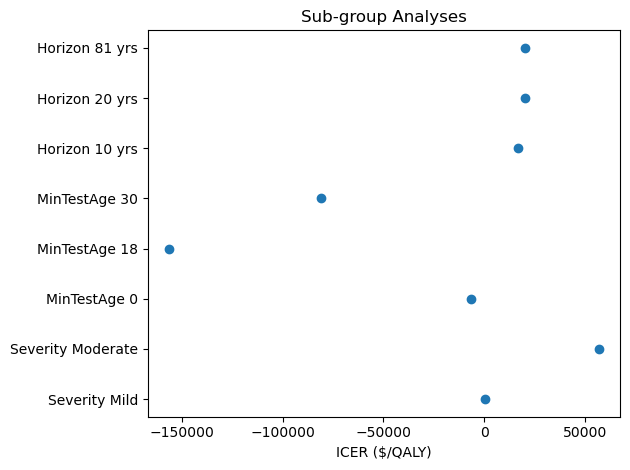

In [16]:
def run_archived_fragment_100(
    *, SEVERITY_DIST, START_YEAR, YEARS, defaul_yield, run_scenario, run_sim
):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 10. Sub-group Analyses  (re-run after Modules 1-9)

    sg = []

    # 1️⃣ severity
    orig = SEVERITY_DIST.copy()
    for sev, label in [(0, "Mild"), (1, "Moderate")]:
        SEVERITY_DIST[:] = cp.array([1.0 if i == sev else 0.0 for i in range(2)])
        dc, dq = run_sim(
            {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15000
        )
        sg.append({"group": f"Severity {label}", "ICER": dc / dq})
    SEVERITY_DIST[:] = orig

    # 2️⃣ age at test
    for age in (0, 18, 30):
        dc, dq = run_sim(
            {"familial_prop": 0.165, "yield_wgs": defaul_yield, "min_test_age": age},
            pop_size=15000,
        )
        sg.append({"group": f"MinTestAge {age}", "ICER": dc / dq})

    # 3️⃣ time-horizon (uses cumulative cost / QALY already stored)
    (_, _), int_full = run_scenario(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15000
    )
    dfp = int_full[int_full["arm"] == "prospective"]
    dfr = int_full[int_full["arm"] == "retrospective"]
    for yrs_n in (10, 20, len(YEARS)):
        yr = START_YEAR + yrs_n - 1
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        sg.append({"group": f"Horizon {yrs_n} yrs", "ICER": (c1 - c0) / (q1 - q0)})

    # ---------- plot ----------
    sg_df = cudf.DataFrame(sg)
    plt.figure()
    plt.errorbar(
        sg_df["ICER"].to_arrow().to_pylist(),
        sg_df["group"].to_arrow().to_pylist(),
        xerr=[0] * len(sg_df),
        fmt="o",
    )
    plt.xlabel("ICER ($/QALY)")
    plt.title("Sub-group Analyses")
    plt.tight_layout()
    plt.show()
    return locals()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

_, mix = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)
pm = mix[mix['arm']=='prospective']
cost_cols = ['cost_health','cost_edu','cost_respite','cost_mobility','cost_welfare','cost_emp','cost_morbidity']
years_host = pm['year'].to_arrow().to_pylist()
data = [pm[col].to_arrow().to_pylist() for col in cost_cols]
plt.figure(); plt.stackplot(years_host, *data, labels=cost_cols); plt.legend(loc='upper left'); plt.title('Cost Mix Over Time (Prospective)'); plt.xlabel('Year'); plt.ylabel('Cumulative Cost'); plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
for u in uptakes:
    _, df = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)
    dfp = df[df['arm']=='prospective']; dfr = df[df['arm']=='retrospective']
    for yr in yrs:
        c1 = float( dfp.loc[dfp['year'] == yr, 'costs'].values[0] )
        c0 = float( dfr.loc[dfr['year'] == yr, 'costs'].values[0] )
        budg.append({'uptake':u,'year':yr,'delta_cost':c1-c0})
budg_df = cudf.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df['uptake']==u]
    yrs_h = sub['year'].to_arrow().to_pylist()
    vals = sub['delta_cost'].to_arrow().to_pylist()
    plt.plot(yrs_h, vals, label=f"Uptake {int(u*100)}%")
plt.title('5-Year Budget Impact'); plt.xlabel('Year'); plt.ylabel('ΔCost'); plt.legend(); plt.show()


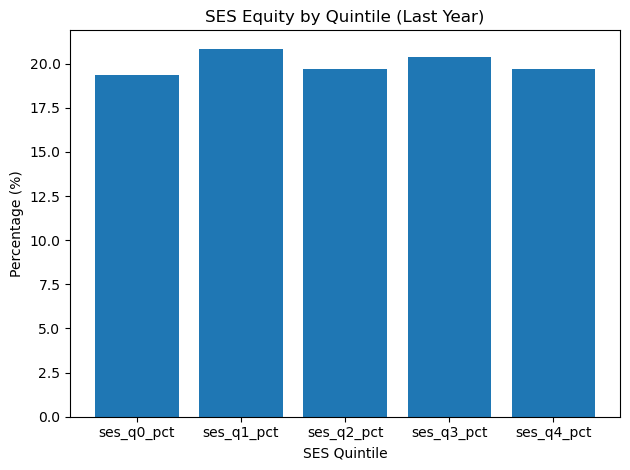

In [21]:
def run_archived_fragment_103(*, YEARS, defaul_yield, run_scenario):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    # 13. Equity by SES Quintile

    eq_int = run_scenario(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20_000
    )[1]

    bas = eq_int[eq_int["arm"] == "prospective"]
    row = bas[bas["year"] == YEARS[-1]].iloc[0]

    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row[col].values[0]) for col in ses_cols]  # scalar floats
    labels = ses_cols

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title("SES Equity by Quintile (Last Year)")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage (%)")
    plt.tight_layout()
    plt.show()
    return locals()

# %% [markdown]
## 14. PSA Histograms

cost_list = psa_df['dCost'].to_arrow().to_pylist()
qaly_list = psa_df['dQALY'].to_arrow().to_pylist()
plt.figure(); plt.hist(cost_list, bins=30); plt.title('PSA ΔCost'); plt.show()
plt.figure(); plt.hist(qaly_list, bins=30); plt.title('PSA ΔQALY'); plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

# reuse wtp and prob from Module 8
prob_host = prob.get().tolist()
ceaf = []
max_so_far = 0.0
for p in prob_host:
    max_so_far = max(max_so_far, p)
    ceaf.append(max_so_far)
plt.figure(); plt.plot(wtp.get().tolist(), ceaf); plt.title('CEAF'); plt.xlabel('WTP'); plt.ylabel('CEAF'); plt.show()


In [25]:
def run_archived_fragment_106(
    *,
    AGE_DIST,
    DISCOUNT,
    FERT_AGE_SPEC,
    MOBILITY,
    MORB_PROB,
    RESPITE,
    U_CARER,
    U_DIAG,
    defaul_yield,
):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    # 16. Input Parameter Summary  ✅

    params = {
        "DISCOUNT": DISCOUNT,
        "default_yield": defaul_yield,
        "U_DIAG": U_DIAG,
        "U_CARER": U_CARER,
        "RESPITE": RESPITE,
        "MOBILITY": MOBILITY,
        # stringify complex structures ↓
        "FERT_AGE_SPEC": json.dumps(
            {f"{k[0]}_{k[1][0]}_{k[1][1]}": v for k, v in FERT_AGE_SPEC.items()}
        ),
        "MORB_PROB": json.dumps(MORB_PROB),
        "AGE_DIST": json.dumps(AGE_DIST.get().tolist()),
    }

    # convert every value to a plain Python string → avoids MixedTypeError
    param_df = cudf.DataFrame(
        {"parameter": list(params.keys()), "value": [str(v) for v in params.values()]}
    )

    param_df.to_csv("input_summary.csv", index=False)
    print("Input parameters saved → input_summary.csv")
    return locals()

Input parameters saved → input_summary.csv


In [27]:
def run_archived_fragment_107(*, det_df):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    # 17. Publication Comparison  ✅  (cuDF-only)

    # Published point estimates you want to compare against
    published = {"base": {"dCost": 50_000, "dQALY": 5.0, "ICER": 10_000}}

    # ---- build a cuDF table from the dict ----
    pub_rows = []
    for scen, vals in published.items():
        pub_rows.append(
            {
                "scenario": scen,
                "dCost_pub": vals["dCost"],
                "dQALY_pub": vals["dQALY"],
                "ICER_pub": vals["ICER"],
            }
        )
    pub_df = cudf.DataFrame(pub_rows)

    # ---- merge with your deterministic simulation output (det_df) ----
    df_cmp = det_df.merge(pub_df, on="scenario", how="left")

    # ---- display ----
    print(df_cmp)  # cuDF native print
    df_cmp.to_csv("publication_comparison.csv", index=False)
    print("Saved → publication_comparison.csv")
    return locals()

  scenario         dCost        dQALY           ICER dCost_pub dQALY_pub  \
0     base -1.150571e+08 -2291.706307   50205.858820     50000       5.0   
1      low  2.232791e+08  1939.728259  115108.438709      <NA>      <NA>   
2     high -2.335490e+08 -2954.609379   79045.648317      <NA>      <NA>   

  ICER_pub  
0    10000  
1     <NA>  
2     <NA>  
Saved → publication_comparison.csv
